<a href="https://colab.research.google.com/github/laiajufresa-code/TFG/blob/main/TFG_LLIBRETA3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LLIBRETA 3 · Models d'Intel·ligència Artificial

**Objectiu:** entrenar, optimitzar, avaluar i comparar **6 models de classificació supervisada** (Logistic Regression, SVM, KNN, Naive Bayes, Random Forest i XGBoost) per predir el nivell de risc de diabetis (Low, Moderate, High, Critical) en **dos escenaris**:

- **Escenari A:** totes les variables predictores originals (32).
- **Escenari B:** només les variables que superen el filtratge de la Llibreta 2 (correlació + capacitat discriminatòria).

*(Els components del PCA queden aparcats per a més endavant.)*

**Estructura (els 5 blocs de l'encàrrec):**

| Bloc | Cel·les |
|---|---|
| 0 · Revisió crítica de les dades | 1 – 3 |
| 1 · Preparació i partició estratificada 80/20 + preprocessament sense *data leakage* | 4 – 6 |
| 2 · Els 6 models | 7 |
| 3 · Validació creuada + Grid Search + estabilitat + avaluació al test | 8 – 9 |
| 4 · Mètriques (Training vs Test) i corbes ROC | 10 – 11 |
| 5 · Escenari A, Escenari B i comparativa final | 12 – 19 |

**Decisions metodològiques preses després de la revisió crítica:**

1. El dataset té **15.000 registres**. S'exclouen `patient_id` i `monitoring_date`: la data augmenta d'hora en hora de manera seqüencial (és un identificador encobert) i no té relació amb el risc (Llibreta 1: ρ = −0,011; p = 0,193). Queden **32 predictores** a l'Escenari A.
2. **Escenari B sense fuita d'informació:** el filtratge de la Llibreta 2 es **repeteix només amb el 80 % d'entrenament** i es compara amb la llista original de la Llibreta 2.
3. Mètrica principal: **F1-score macro** (mitjana de l'F1 de les 4 classes amb el mateix pes). Les classes estan desequilibrades (40/30/20/10 %), i el macro evita que la classe *Critical* quedi amagada. L'F1 equilibra **precisió** i **sensibilitat**. Per això s'afegeix també l'**especificitat** com a mètrica complementària.
4. **SVM:** la cerca d'hiperparàmetres es fa sense probabilitats (l'F1 no les necessita, i `probability=True` multiplica per 5 el temps). Per a l'avaluació per caixes, el model final i les corbes ROC es fa servir `probability=True`. Les prediccions de classe (i, per tant, l'F1) no canvien.
5. Desequilibri: `class_weight` (`None` / `"balanced"`) s'inclou com a hiperparàmetre de LR, SVM i RF.
6. Els 3 registres amb durada de diabetis > edat **es mantenen**: la Llibreta 1 va demostrar que no afecten els resultats (canvi màxim de ε² = 0,0006).
7. Mètrica addicional: **kappa ponderat quadràtic**, perquè les classes estan ordenades (confondre Low amb Critical és més greu que confondre High amb Critical).

⏱️ **Temps aproximat a Colab:** 30–60 minuts per escenari (l'SVM és el model més lent). Per provar que tot funciona abans de la versió definitiva, posa `MODE_RAPID = True` a la Cel·la 2.

## BLOC 0 · Revisió crítica de les dades
### Cel·la 1 · Llibreries i càrrega

In [ ]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, cohen_kappa_score, classification_report)
from xgboost import XGBClassifier
import sklearn, xgboost
import kagglehub

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None); pd.set_option("display.width", 250)

path = kagglehub.dataset_download("colabsss/diabetes-risk-monitoring-dataset")
csv_path = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)[0]
df_raw = pd.read_csv(csv_path)
print("Dades:", df_raw.shape, "· scikit-learn", sklearn.__version__, "· xgboost", xgboost.__version__)

100%|██████████| 975k/975k [00:00<00:00, 64.7MB/s]

Extracting files...


Dades: (15000, 35) · scikit-learn 1.6.1 · xgboost 3.4.1


### Cel·la 2 · Paràmetres (es canvien NOMÉS aquí)

In [ ]:
# ======================= PARÀMETRES =======================
SEED       = 42          # llavor: partició, caixes i models -> resultats reproduïbles
TEST_SIZE  = 0.20        # 80 % training / 20 % test
K_FOLDS    = 5           # caixes de la validació creuada estratificada
METRICA    = "f1_macro"  # mètrica que maximitza el Grid Search
N_JOBS     = -1          # tots els nuclis de Colab
MODE_RAPID = False       # True = graelles mínimes per provar que tot funciona (NO per als resultats finals)

ESCENARI_B_FONT = "train"   # "train" = filtratge de la Llibreta 2 repetit només amb el 80 % (sense fuita)
                            # "llibreta2" = llista fixa obtinguda a la Llibreta 2 (amb totes les dades)
LLINDAR_CORR = 0.70         # mateix criteri que la Llibreta 2
ALPHA        = 0.05
LLINDAR_SD_ESTABLE = 0.02   # es considera estable si la SD de l'F1 entre caixes és < 0,02
# ==========================================================

TARGET = "diabetes_risk_level"
ORDER  = ["Low_Risk", "Moderate_Risk", "High_Risk", "Critical_Risk"]
ETIQ   = ["Low", "Moderate", "High", "Critical"]
PAL4   = ["#2ca02c", "#f2c94c", "#f2994a", "#d62728"]

ID_COLS   = ["patient_id", "monitoring_date"]
CAT_BIN   = ["gender", "family_history_diabetes", "medication_change_recent"]
DISC_COLS = ["comorbidity_count", "abnormal_glucose_events", "previous_hypoglycemia_events",
             "outpatient_visits_6m", "daily_monitoring_frequency"]

# Variables supervivents de la Llibreta 2 (32 -> 28 per correlació -> 21 per significació)
VARS_LLIBRETA2 = ['age', 'bmi', 'glucose_fasting_mg_dl', 'hba1c_percent', 'heart_rate_bpm', 'systolic_bp_mmhg',
                  'diastolic_bp_mmhg', 'spo2_percent', 'physical_activity_min', 'calories_burned',
                  'sleep_duration_hr', 'sleep_quality_score', 'sedentary_duration_hr', 'carbohydrate_intake_g',
                  'medication_adherence_pct', 'insulin_dose_units', 'stress_level_score',
                  'sensor_glucose_variability', 'heart_rate_variability_ms', 'abnormal_glucose_events',
                  'previous_hypoglycemia_events']

assert ESCENARI_B_FONT in ("train", "llibreta2") and 0 < TEST_SIZE < 1 and K_FOLDS >= 2
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "axes.labelsize": 10})
np.random.seed(SEED)

### Cel·la 3 · Revisió crítica de l'estructura de les dades
Abans de programar els models es comprova tot allò que podria invalidar els resultats: valors perduts, duplicats, tipus de variables (categòriques que cal codificar), columnes que no s'han de fer servir, i si la classe minoritària té prou casos a cada caixa.

In [ ]:
print("=" * 90); print("REVISIÓ CRÍTICA DE LES DADES"); print("=" * 90)

# 1) Mida, valors perduts i duplicats
print(f"1) Registres: {df_raw.shape[0]} · columnes: {df_raw.shape[1]}")
print(f"   Valors perduts (NaN): {int(df_raw.isna().sum().sum())} · files duplicades: {int(df_raw.duplicated().sum())}")

# 2) Tipus de cada columna
tipus = []
for c in df_raw.columns:
    if c in ID_COLS:      t, us = "identificador / data", "S'EXCLOU"
    elif c == TARGET:     t, us = "variable objectiu", "y"
    elif c in CAT_BIN:    t, us = "categòrica binària", "OneHotEncoder"
    elif c in DISC_COLS:  t, us = "numèrica discreta", "StandardScaler"
    else:                 t, us = "numèrica contínua", "StandardScaler"
    tipus.append({"columna": c, "dtype": str(df_raw[c].dtype), "tipus": t, "valors únics": df_raw[c].nunique(),
                  "exemple": ", ".join(map(str, sorted(df_raw[c].unique())[:2])) if df_raw[c].nunique() <= 4 else "", "tractament": us})
tipus = pd.DataFrame(tipus).set_index("columna")
print("\n2) Tipus de variables i tractament al Pipeline:"); display(tipus)

text_no_previst = [c for c in df_raw.columns if df_raw[c].dtype == object and c not in CAT_BIN + ID_COLS + [TARGET]]
print("   Variables de text no previstes (s'haurien de codificar):", text_no_previst if text_no_previst else "cap ✔")

# 3) Per què s'exclou monitoring_date
d = pd.to_datetime(df_raw["monitoring_date"])
print("\n3) monitoring_date: dates úniques =", d.nunique(), "· salt entre registres consecutius:", {str(k): v for k, v in d.diff().dropna().value_counts().items()},
      "\n   -> és seqüencial (com un número de fila): s'exclou igual que patient_id.")

# 4) Classes i casos de la classe minoritària a cada caixa
cnt = df_raw[TARGET].value_counts().reindex(ORDER)
print("\n4) Distribució de la classe objectiu:")
display(pd.DataFrame({"n": cnt, "%": (cnt / len(df_raw) * 100).round(1)}))
n_min_train = cnt.min() * (1 - TEST_SIZE)
print(f"   Classe minoritària ({cnt.idxmin()}): {cnt.min()} casos -> ≈{n_min_train:.0f} al training -> "
      f"≈{n_min_train / K_FOLDS:.0f} a cada caixa de validació. Amb estratificació, n'hi ha prou ✔")
print("   Les classes NO estan balancejades (40/30/20/10 %) -> mètrica principal: F1 macro + class_weight al Grid Search.")

# 5) Registres impossibles (es mantenen, justificat a la Llibreta 1)
imp = df_raw["diabetes_duration_years"] > df_raw["age"]
print(f"\n5) Registres amb durada de diabetis > edat: {int(imp.sum())} -> es mantenen (Llibreta 1: no afecten els resultats).")

REVISIÓ CRÍTICA DE LES DADES
1) Registres: 15000 · columnes: 35
   Valors perduts (NaN): 0 · files duplicades: 0

2) Tipus de variables i tractament al Pipeline:


,dtype,tipus,valors únics,exemple,tractament
columna,,,,,
patient_id,object,identificador / data,15000,,S'EXCLOU
monitoring_date,object,identificador / data,15000,,S'EXCLOU
age,int64,numèrica contínua,63,,StandardScaler
gender,object,categòrica binària,2,"Female, Male",OneHotEncoder
bmi,float64,numèrica contínua,243,,StandardScaler
family_history_diabetes,object,categòrica binària,2,"No, Yes",OneHotEncoder
diabetes_duration_years,float64,numèrica contínua,222,,StandardScaler
glucose_fasting_mg_dl,float64,numèrica contínua,1063,,StandardScaler
glucose_postprandial_mg_dl,float64,numèrica contínua,1829,,StandardScaler


   Variables de text no previstes (s'haurien de codificar): cap ✔

3) monitoring_date: dates úniques = 15000 · salt entre registres consecutius: {'0 days 01:00:00': 14999} 
   -> és seqüencial (com un número de fila): s'exclou igual que patient_id.

4) Distribució de la classe objectiu:


,n,%
diabetes_risk_level,,
Low_Risk,6000,40.0
Moderate_Risk,4500,30.0
High_Risk,3000,20.0
Critical_Risk,1500,10.0


   Classe minoritària (Critical_Risk): 1500 casos -> ≈1200 al training -> ≈240 a cada caixa de validació. Amb estratificació, n'hi ha prou ✔
   Les classes NO estan balancejades (40/30/20/10 %) -> mètrica principal: F1 macro + class_weight al Grid Search.

5) Registres amb durada de diabetis > edat: 3 -> es mantenen (Llibreta 1: no afecten els resultats).


## BLOC 1 · Preparació i partició estratificada (80 / 20)
### Cel·la 4 · Variables predictores (X) i variable objectiu (y)

In [ ]:
X = df_raw.drop(columns=ID_COLS + [TARGET]).copy()
PREDICTORES = list(X.columns)

# y codificada 0-3 respectant l'ordre clínic (XGBoost necessita etiquetes 0..K-1)
y = pd.Series(pd.Categorical(df_raw[TARGET], categories=ORDER, ordered=True).codes, index=X.index, name="risc")
assert (y >= 0).all(), "Hi ha alguna etiqueta de risc no prevista"
assert len(PREDICTORES) == 32 and not set(PREDICTORES) & set(ID_COLS + [TARGET])
print("Predictores (Escenari A):", len(PREDICTORES))
print("Codificació de y:", dict(enumerate(ETIQ)))

Predictores (Escenari A): 32
Codificació de y: {0: 'Low', 1: 'Moderate', 2: 'High', 3: 'Critical'}


### Cel·la 5 · Partició estratificada 80/20 i caixes de la validació creuada
`stratify=y` fa que el training i el test tinguin la mateixa proporció de cada classe que la mostra original. Les 5 caixes es generen **una sola vegada** i es fan servir per a tots els models i tots dos escenaris, de manera que la comparació es fa exactament amb les mateixes dades.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

def taula_classes(*parts):
    t = {}
    for nom, s in parts:
        c = s.value_counts().reindex(range(4), fill_value=0)
        t[(nom, "n")] = list(c.values) + [len(s)]
        t[(nom, "%")] = list((c / len(s) * 100).round(2).values) + [100.0]
    return pd.DataFrame(t, index=ETIQ + ["Total"])

print(f"PARTICIÓ ESTRATIFICADA · training {1 - TEST_SIZE:.0%} / test {TEST_SIZE:.0%} · random_state = {SEED}")
display(taula_classes(("Mostra completa", y), ("Training (80 %)", y_train), ("Test (20 %)", y_test)))

# Caixes de la validació creuada (dins del training)
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(X_train, y_train))        # llista fixa: mateixes caixes per a tot
print(f"\nVALIDACIÓ CREUADA ESTRATIFICADA · {K_FOLDS} caixes: s'entrena amb {K_FOLDS - 1} i es valida amb la restant")
display(taula_classes(*[(f"Caixa {i+1} (validació)", y_train.iloc[iva]) for i, (_, iva) in enumerate(FOLDS)]))

PARTICIÓ ESTRATIFICADA · training 80% / test 20% · random_state = 42


Mostra completa        Training (80 %)        Test (20 %)       
                       n      %               n      %           n      %
Low                 6000   40.0            4800   40.0        1200   40.0
Moderate            4500   30.0            3600   30.0         900   30.0
High                3000   20.0            2400   20.0         600   20.0
Critical            1500   10.0            1200   10.0         300   10.0
Total              15000  100.0           12000  100.0        3000  100.0


VALIDACIÓ CREUADA ESTRATIFICADA · 5 caixes: s'entrena amb 4 i es valida amb la restant


Caixa 1 (validació)        Caixa 2 (validació)        Caixa 3 (validació)        Caixa 4 (validació)        Caixa 5 (validació)       
                           n      %                   n      %                   n      %                   n      %                   n      %
Low                      960   40.0                 960   40.0                 960   40.0                 960   40.0                 960   40.0
Moderate                 720   30.0                 720   30.0                 720   30.0                 720   30.0                 720   30.0
High                     480   20.0                 480   20.0                 480   20.0                 480   20.0                 480   20.0
Critical                 240   10.0                 240   10.0                 240   10.0                 240   10.0                 240   10.0
Total                   2400  100.0                2400  100.0                2400  100.0                2400  100.0                2400  100.0

### Cel·la 6 · Escenari B: filtratge de la Llibreta 2 repetit només amb el training
Es reprodueix exactament el procediment de la Llibreta 2, però **només amb el 80 % d'entrenament**:
1. Per a cada parella amb |ρ de Spearman| ≥ 0,70, s'elimina la variable amb menys efecte sobre el risc (ε² de Kruskal-Wallis).
2. S'eliminen les variables sense diferències significatives entre grups de risc (Kruskal-Wallis o khi quadrat, amb p ajustat per Holm).

Al final es compara amb la llista de la Llibreta 2.

In [ ]:
def holm(p):
    p = np.asarray(p, float); n = len(p); ordre = np.argsort(p); adj = np.empty(n); mx = 0.0
    for rang, i in enumerate(ordre):
        mx = max(mx, (n - rang) * p[i]); adj[i] = min(mx, 1.0)
    return adj

def eps2_kw(grups):
    H = stats.kruskal(*grups)[0]; N = sum(len(g) for g in grups); k = len(grups)
    return (H - k + 1) / (N - k)

def filtratge_llibreta2(Xtr, ytr):
    Xc = Xtr.copy()                                            # binàries 0/1 només per a la correlació
    Xc["gender"] = (Xc["gender"] == "Male").astype(int)
    for c in ["family_history_diabetes", "medication_change_recent"]:
        Xc[c] = (Xc[c] == "Yes").astype(int)
    efecte = pd.Series({c: eps2_kw([Xc.loc[ytr == k, c].values for k in range(4)]) for c in Xc.columns})

    # PAS 1 · correlació
    corr = Xc.corr(method="spearman"); queden = list(Xc.columns); reg = []
    while True:
        sub = corr.loc[queden, queden].abs().values.copy(); np.fill_diagonal(sub, 0)
        i, j = np.unravel_index(np.argmax(sub), sub.shape)
        if sub[i, j] < LLINDAR_CORR: break
        a, b = queden[i], queden[j]
        elim, mant = (a, b) if efecte[a] < efecte[b] else (b, a)
        reg.append({"parella": f"{a} ~ {b}", "rho": round(corr.loc[a, b], 3), "s'elimina": elim, "es manté": mant})
        queden.remove(elim)

    # PAS 2 · significació (Holm)
    files = []
    for c in queden:
        if c in CAT_BIN:
            p = stats.chi2_contingency(pd.crosstab(Xtr[c], ytr))[1]; t = "Khi quadrat"
        else:
            p = stats.kruskal(*[Xtr.loc[ytr == k, c].values for k in range(4)])[1]; t = "Kruskal-Wallis"
        files.append({"variable": c, "test": t, "p": p, "ε²": efecte[c]})
    sig = pd.DataFrame(files).set_index("variable"); sig["p_holm"] = holm(sig["p"])
    finals = [c for c in queden if sig.loc[c, "p_holm"] < ALPHA]
    return finals, pd.DataFrame(reg), sig

vars_train, reg_corr, taula_sig = filtratge_llibreta2(X_train, y_train)
print("PAS 1 (correlació, només training):"); display(reg_corr)
print("PAS 2 · variables eliminades per no ser significatives:",
      list(taula_sig.index[taula_sig["p_holm"] >= ALPHA]))

nomes_train, nomes_l2 = sorted(set(vars_train) - set(VARS_LLIBRETA2)), sorted(set(VARS_LLIBRETA2) - set(vars_train))
print(f"\nFiltratge amb el training: {len(vars_train)} variables · Llibreta 2 (totes les dades): {len(VARS_LLIBRETA2)} variables")
print("Coincideixen exactament ✔" if not nomes_train and not nomes_l2 else
      f"DIFERÈNCIES -> només al training: {nomes_train} · només a la Llibreta 2: {nomes_l2}")

VARS_A = PREDICTORES
VARS_B = [c for c in PREDICTORES if c in (vars_train if ESCENARI_B_FONT == "train" else VARS_LLIBRETA2)]
print(f"\nEscenari A: {len(VARS_A)} variables · Escenari B: {len(VARS_B)} variables (font: {ESCENARI_B_FONT})")

PAS 1 (correlació, només training):


,parella,rho,s'elimina,es manté
0,physical_activity_min ~ step_count,0.830,step_count,physical_activity_min
1,age ~ comorbidity_count,0.740,comorbidity_count,age
2,diabetes_duration_years ~ insulin_dose_units,0.726,diabetes_duration_years,insulin_dose_units


PAS 2 · variables eliminades per no ser significatives: ['gender', 'family_history_diabetes', 'body_temperature_c', 'water_intake_l', 'daily_monitoring_frequency', 'outpatient_visits_6m', 'medication_change_recent']

Filtratge amb el training: 22 variables · Llibreta 2 (totes les dades): 21 variables
DIFERÈNCIES -> només al training: ['glucose_postprandial_mg_dl'] · només a la Llibreta 2: []

Escenari A: 32 variables · Escenari B: 22 variables (font: train)


## BLOC 2 · Els 6 models de classificació
### Cel·la 7 · Preprocessament (Pipeline) i graelles d'hiperparàmetres
Cada model va dins d'un `Pipeline` = **preprocessament + model**. Dins del `GridSearchCV`, el Pipeline es torna a ajustar a cada caixa. Així, el `StandardScaler` (mitjana i desviació) i l'`OneHotEncoder` aprenen **només de les caixes d'entrenament**, i mai de la caixa de validació ni del test. Això evita el *data leakage*.

- **Numèriques (contínues i discretes):** `StandardScaler`.
- **Categòriques binàries:** `OneHotEncoder(drop="if_binary")` (una sola columna 0/1 per variable).
- **XGBoost** no té `class_weight`, però gestiona bé el desequilibri amb els arbres de *boosting*.

In [ ]:
def preprocessador(cols):
    num = [c for c in cols if c not in CAT_BIN]
    cat = [c for c in cols if c in CAT_BIN]
    trans = [("num", StandardScaler(), num)]
    if cat:
        trans.append(("cat", OneHotEncoder(drop="if_binary", sparse_output=False), cat))
    return ColumnTransformer(trans, remainder="drop")

CW = [None, "balanced"]
if not MODE_RAPID:
    MODELS = {
        "Logistic Regression": (LogisticRegression(max_iter=5000, random_state=SEED),
                                {"model__C": [0.01, 0.1, 1, 10, 100], "model__class_weight": CW}),
        "SVM": (SVC(kernel="rbf", probability=False, random_state=SEED),          # probability=True a l'avaluació
                {"model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01, 0.1], "model__class_weight": CW}),
        "KNN": (KNeighborsClassifier(),
                {"model__n_neighbors": [5, 11, 21, 31, 51], "model__weights": ["uniform", "distance"],
                 "model__metric": ["euclidean", "manhattan"]}),
        "Naive Bayes": (GaussianNB(), {"model__var_smoothing": np.logspace(-9, -3, 7)}),
        "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=1),
                          {"model__n_estimators": [200, 400], "model__max_depth": [None, 12],
                           "model__min_samples_leaf": [1, 4], "model__class_weight": CW}),
        "XGBoost": (XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
                                  random_state=SEED, n_jobs=1),
                    {"model__n_estimators": [200, 400], "model__max_depth": [3, 5],
                     "model__learning_rate": [0.05, 0.1], "model__subsample": [0.8, 1.0]}),
    }
else:   # graelles mínimes, només per comprovar que el codi funciona
    MODELS = {
        "Logistic Regression": (LogisticRegression(max_iter=5000, random_state=SEED), {"model__C": [1]}),
        "SVM": (SVC(kernel="rbf", probability=False, random_state=SEED), {"model__C": [1]}),
        "KNN": (KNeighborsClassifier(), {"model__n_neighbors": [11]}),
        "Naive Bayes": (GaussianNB(), {"model__var_smoothing": [1e-9]}),
        "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1), {"model__max_depth": [None]}),
        "XGBoost": (XGBClassifier(objective="multi:softprob", eval_metric="mlogloss", tree_method="hist",
                                  n_estimators=100, random_state=SEED, n_jobs=1), {"model__max_depth": [3]}),
    }

resum_graella = pd.DataFrame({m: {"hiperparàmetres": ", ".join(k.replace("model__", "") for k in g),
                                  "combinacions": int(np.prod([len(v) for v in g.values()])),
                                  "entrenaments (× caixes)": int(np.prod([len(v) for v in g.values()])) * K_FOLDS}
                              for m, (_, g) in MODELS.items()}).T
print("MODE_RAPID =", MODE_RAPID); display(resum_graella)

MODE_RAPID = False


,hiperparàmetres,combinacions,entrenaments (× caixes)
Logistic Regression,"C, class_weight",10,50
SVM,"C, gamma, class_weight",18,90
KNN,"n_neighbors, weights, metric",20,100
Naive Bayes,var_smoothing,7,35
Random Forest,"n_estimators, max_depth, min_samples_leaf, cla...",16,80
XGBoost,"n_estimators, max_depth, learning_rate, subsample",16,80


## BLOC 3 · Entrenament: validació creuada, Grid Search i estabilitat
### Cel·la 8 · Funcions de mètriques
- **Accuracy:** proporció de pacients ben classificats.
- **Precision (macro):** de tots els que el model assigna a una classe, quants hi pertanyen de debò (mitjana de les 4 classes).
- **Recall = Sensitivity (macro):** de tots els pacients d'una classe, quants en detecta el model.
- **F1-score (macro):** mitjana harmònica de precisió i sensibilitat. És la **mètrica principal**.
- **AUC (One-vs-Rest, macro):** àrea sota la corba ROC de cada classe contra la resta.
- *Complementàries:* **especificitat** (macro) i **kappa ponderat quadràtic** (té en compte l'ordre de les classes).

In [ ]:
METRIQUES = ["Accuracy", "Precision", "Recall (Sensitivity)", "F1-score", "AUC", "Specificity", "Kappa ponderat"]
FPR_GRID = np.linspace(0, 1, 201)          # eix comú per fer la mitjana de les corbes ROC entre caixes

def especificitat_macro(yt, yp):
    cm = confusion_matrix(yt, yp, labels=range(4)); esp = []
    for k in range(4):
        tp = cm[k, k]; fn = cm[k].sum() - tp; fp = cm[:, k].sum() - tp; tn = cm.sum() - tp - fn - fp
        esp.append(tn / (tn + fp))
    return float(np.mean(esp))

def metriques(yt, yp, proba):
    return {"Accuracy": accuracy_score(yt, yp),
            "Precision": precision_score(yt, yp, average="macro", zero_division=0),
            "Recall (Sensitivity)": recall_score(yt, yp, average="macro", zero_division=0),
            "F1-score": f1_score(yt, yp, average="macro", zero_division=0),
            "AUC": roc_auc_score(yt, proba, multi_class="ovr", average="macro", labels=range(4)),
            "Specificity": especificitat_macro(yt, yp),
            "Kappa ponderat": cohen_kappa_score(yt, yp, weights="quadratic")}

def roc_interpolada(yt, proba):
    # TPR de cada classe (One-vs-Rest) interpolada sobre FPR_GRID + AUC de cada classe
    corbes, aucs = {}, {}
    for k in range(4):
        fpr, tpr, _ = roc_curve(np.asarray(yt) == k, proba[:, k])
        t = np.interp(FPR_GRID, fpr, tpr); t[0] = 0.0
        corbes[k], aucs[k] = t, roc_auc_score(np.asarray(yt) == k, proba[:, k])
    return corbes, aucs

### Cel·la 9 · Funció principal: Grid Search + avaluació per caixes + test
Per a **cada model**, la funció fa el següent:
1. **`GridSearchCV`** prova totes les combinacions d'hiperparàmetres amb les 5 caixes (entrena amb 4 i valida amb la restant, rotant) i tria la que dona l'**F1 macro** més alt.
2. **Control d'estabilitat:** amb els millors hiperparàmetres, torna a recórrer les 5 caixes i **imprimeix el resultat de cada caixa**. Guarda totes les mètriques i les probabilitats de validació (per a la ROC del training amb ± 1 SD). També calcula el rendiment sobre les caixes d'entrenament, per detectar sobreajust.
3. **Model final:** l'entrena una sola vegada amb tot el 80 % de training i l'aplica directament al 20 % de test, **sense tornar-lo a entrenar**.

La selecció del millor model es fa amb la validació creuada. El test només serveix per confirmar el resultat.

In [ ]:
def executar_escenari(nom_esc, cols):
    Xtr, Xte = X_train[cols], X_test[cols]
    res = {}
    print("=" * 100); print(f"ESCENARI {nom_esc} · {len(cols)} variables"); print("=" * 100)
    for nom, (estimador, graella) in MODELS.items():
        t0 = time.time()
        pipe = Pipeline([("prep", preprocessador(cols)), ("model", clone(estimador))])

        # 1) Grid Search amb validació creuada estratificada
        gs = GridSearchCV(pipe, graella, scoring=METRICA, cv=FOLDS, n_jobs=N_JOBS, refit=False, return_train_score=True)
        gs.fit(Xtr, y_train)
        millors = gs.best_params_
        f1_grid = [gs.cv_results_[f"split{f}_test_score"][gs.best_index_] for f in range(K_FOLDS)]

        # 2) Avaluació caixa per caixa amb els millors hiperparàmetres
        millor = clone(pipe).set_params(**millors)
        if nom == "SVM":
            millor.set_params(model__probability=True)
        val, entr, rocs, aucs = [], [], [], []
        print(f"\n▶ {nom} · millors hiperparàmetres: { {k.replace('model__', ''): v for k, v in millors.items()} }")
        for f, (itr, iva) in enumerate(FOLDS):
            m = clone(millor).fit(Xtr.iloc[itr], y_train.iloc[itr])
            pv = m.predict_proba(Xtr.iloc[iva])
            val.append(metriques(y_train.iloc[iva], m.predict(Xtr.iloc[iva]), pv))
            entr.append(metriques(y_train.iloc[itr], m.predict(Xtr.iloc[itr]), m.predict_proba(Xtr.iloc[itr])))
            c, a = roc_interpolada(y_train.iloc[iva], pv); rocs.append(c); aucs.append(a)
            print(f"   Caixa {f+1}/{K_FOLDS} · F1 = {val[-1]['F1-score']:.4f} · Accuracy = {val[-1]['Accuracy']:.4f} · "
                  f"AUC = {val[-1]['AUC']:.4f}   (F1 a les caixes d'entrenament = {entr[-1]['F1-score']:.4f})")
        val, entr = pd.DataFrame(val, index=[f"Caixa {i+1}" for i in range(K_FOLDS)]), pd.DataFrame(entr)
        if not np.allclose(val["F1-score"].values, f1_grid, atol=1e-4):     # comprovació de reproductibilitat
            print("   ⚠ L'F1 per caixa no coincideix exactament amb el del Grid Search:", np.round(f1_grid, 4))

        # 3) Model final: entrenat amb TOT el training i aplicat UNA vegada al test
        final = clone(millor).fit(Xtr, y_train)
        p_te = final.predict_proba(Xte); y_pred = final.predict(Xte)
        test = metriques(y_test, y_pred, p_te)

        sd = val["F1-score"].std(ddof=1)
        print(f"   ➜ F1 CV = {val['F1-score'].mean():.4f} ± {sd:.4f} (rang {val['F1-score'].min():.4f}–{val['F1-score'].max():.4f}) · "
              f"{'ESTABLE ✔' if sd < LLINDAR_SD_ESTABLE else 'POC ESTABLE ✘'} · F1 Test = {test['F1-score']:.4f} · {time.time() - t0:.0f} s")
        res[nom] = {"params": millors, "cv_val": val, "cv_train": entr, "test": test, "roc_folds": rocs,
                    "auc_folds": aucs, "proba_test": p_te, "pred_test": y_pred, "model_final": final,
                    "temps_s": time.time() - t0, "grid": pd.DataFrame(gs.cv_results_)}
    return res

## BLOC 4 · Mètriques (Training vs Test) i corbes ROC
### Cel·la 10 · Funcions de taules
- **Training:** mitjana ± SD de les 5 caixes de validació.
- **Test:** un únic valor.

In [ ]:
def taula_resultats(res):
    files = {}
    for m, r in res.items():
        fila = {}
        for met in METRIQUES:
            fila[(met, "Training (CV) mitjana ± SD")] = f"{r['cv_val'][met].mean():.4f} ± {r['cv_val'][met].std(ddof=1):.4f}"
            fila[(met, "Test")] = f"{r['test'][met]:.4f}"
        files[m] = fila
    t = pd.DataFrame.from_dict(files, orient="index"); t.columns = pd.MultiIndex.from_tuples(t.columns)
    return t

def taula_estabilitat(res):
    t = pd.DataFrame({m: r["cv_val"]["F1-score"] for m, r in res.items()}).T.round(4)
    t["mitjana"] = t.mean(axis=1).round(4); t["SD"] = t.iloc[:, :K_FOLDS].std(axis=1, ddof=1).round(4)
    t["rang (màx-mín)"] = (t.iloc[:, :K_FOLDS].max(axis=1) - t.iloc[:, :K_FOLDS].min(axis=1)).round(4)
    t["estable"] = np.where(t["SD"] < LLINDAR_SD_ESTABLE, "✔", "✘")
    return t

def taula_sobreajust(res):
    return pd.DataFrame({m: {"F1 caixes d'entrenament": r["cv_train"]["F1-score"].mean(),
                             "F1 caixes de validació": r["cv_val"]["F1-score"].mean(),
                             "F1 test": r["test"]["F1-score"],
                             "diferència entrenament - test": r["cv_train"]["F1-score"].mean() - r["test"]["F1-score"]}
                         for m, r in res.items()}).T.round(4)

def taula_auc_classe(res):
    t = {}
    for m, r in res.items():
        for k in range(4):
            a = [af[k] for af in r["auc_folds"]]
            t.setdefault(m, {})[(ETIQ[k], "Training")] = f"{np.mean(a):.4f} ± {np.std(a, ddof=1):.4f}"
            t[m][(ETIQ[k], "Test")] = f"{roc_auc_score(y_test == k, r['proba_test'][:, k]):.4f}"
    t = pd.DataFrame.from_dict(t, orient="index"); t.columns = pd.MultiIndex.from_tuples(t.columns)
    return t

def taula_params(res):
    return pd.DataFrame({m: {k.replace("model__", ""): str(v) for k, v in r["params"].items()} for m, r in res.items()}).T.fillna("—")

def mostrar_taules(res, nom_esc):
    print(f"ESCENARI {nom_esc} · TAULA DE MÈTRIQUES (Training = mitjana ± SD de {K_FOLDS} caixes · Test = valor únic)")
    display(taula_resultats(res))
    print("\nCONTROL D'ESTABILITAT · F1 macro de cada caixa de validació"); display(taula_estabilitat(res))
    print("\nAUC PER CLASSE (One-vs-Rest)"); display(taula_auc_classe(res))
    print("\nCOMPROVACIÓ DE SOBREAJUST (F1 macro)"); display(taula_sobreajust(res))
    print("\nMILLORS HIPERPARÀMETRES (Grid Search)"); display(taula_params(res))

### Cel·la 11 · Funcions de gràfics: corbes ROC, matrius de confusió i estabilitat
- **ROC per model:** un gràfic per classe. La línia de color és la corba mitjana del training, amb la banda de ± 1 SD entre caixes. La línia negra discontínua és el test, i la diagonal grisa és l'atzar (AUC = 0,5).
- **ROC resum:** la corba *macro* (mitjana de les 4 classes) dels 6 models, per veure quin s'acosta més a la cantonada superior esquerra.

In [ ]:
COL_MODELS = dict(zip(MODELS, ["#4C78A8", "#E45756", "#72B7B2", "#B279A2", "#54A24B", "#F58518"]))

def plot_roc_model(res, nom, nom_esc):
    r = res[nom]; fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
    for k, ax in enumerate(axes):
        T = np.array([c[k] for c in r["roc_folds"]]); mu, sd = T.mean(0), T.std(0, ddof=1)
        a_cv = [a[k] for a in r["auc_folds"]]
        ax.plot(FPR_GRID, mu, color=PAL4[k], lw=2.2, label=f"Training (CV): AUC = {np.mean(a_cv):.3f} ± {np.std(a_cv, ddof=1):.3f}")
        ax.fill_between(FPR_GRID, np.clip(mu - sd, 0, 1), np.clip(mu + sd, 0, 1), color=PAL4[k], alpha=0.3, label="± 1 SD entre caixes")
        fpr, tpr, _ = roc_curve(y_test == k, r["proba_test"][:, k])
        ax.plot(fpr, tpr, "k--", lw=1.5, label=f"Test: AUC = {roc_auc_score(y_test == k, r['proba_test'][:, k]):.3f}")
        ax.plot([0, 1], [0, 1], ":", color="grey", lw=1.2, label="Atzar (AUC = 0,5)")
        ax.set(xlim=(-0.01, 1), ylim=(0, 1.01), xlabel="1 - Especificitat (FPR)", ylabel="Sensibilitat (TPR)",
               title=f"{ETIQ[k]} vs resta"); ax.legend(loc="lower right", fontsize=8)
    fig.suptitle(f"Escenari {nom_esc} · {nom} · corbes ROC One-vs-Rest", fontsize=13, fontweight="bold", y=1.03)
    plt.tight_layout(); plt.show()

def plot_roc_resum(res, nom_esc):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
    for nom, r in res.items():
        M = np.array([np.mean([c[k] for k in range(4)], axis=0) for c in r["roc_folds"]])    # macro per caixa
        mu, sd = M.mean(0), M.std(0, ddof=1)
        axes[0].plot(FPR_GRID, mu, color=COL_MODELS[nom], lw=2,
                     label=f"{nom}: AUC = {r['cv_val']['AUC'].mean():.3f} ± {r['cv_val']['AUC'].std(ddof=1):.3f}")
        axes[0].fill_between(FPR_GRID, np.clip(mu - sd, 0, 1), np.clip(mu + sd, 0, 1), color=COL_MODELS[nom], alpha=0.2)
        c_te, _ = roc_interpolada(y_test, r["proba_test"])
        axes[1].plot(FPR_GRID, np.mean([c_te[k] for k in range(4)], axis=0), color=COL_MODELS[nom], lw=2,
                     label=f"{nom}: AUC = {r['test']['AUC']:.3f}")
    for ax, t in zip(axes, ["Training (CV): mitjana ± 1 SD", "Test"]):
        ax.plot([0, 1], [0, 1], ":", color="grey", label="Atzar (AUC = 0,5)")
        ax.set(xlim=(-0.01, 1), ylim=(0, 1.01), xlabel="1 - Especificitat (FPR)", ylabel="Sensibilitat (TPR)",
               title=f"ROC macro (mitjana de les 4 classes) · {t}"); ax.legend(loc="lower right", fontsize=9)
    fig.suptitle(f"Escenari {nom_esc} · comparativa ROC dels 6 models", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

def plot_confusio(res, nom_esc):
    fig, axes = plt.subplots(2, 3, figsize=(17, 10))
    for ax, (nom, r) in zip(axes.ravel(), res.items()):
        cm = confusion_matrix(y_test, r["pred_test"], labels=range(4))
        cmn = cm / cm.sum(axis=1, keepdims=True)
        annot = np.array([[f"{cm[i, j]}\n({cmn[i, j]:.1%})" for j in range(4)] for i in range(4)])
        sns.heatmap(cmn, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                    xticklabels=ETIQ, yticklabels=ETIQ, annot_kws={"size": 9})
        ax.set(title=f"{nom} · F1 test = {r['test']['F1-score']:.3f}", xlabel="Predit", ylabel="Real")
    fig.suptitle(f"Escenari {nom_esc} · matrius de confusió al test (n i % per fila real)", fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

def plot_estabilitat(res, nom_esc):
    d = pd.concat([pd.DataFrame({"Model": m, "F1": r["cv_val"]["F1-score"].values}) for m, r in res.items()])
    fig, ax = plt.subplots(figsize=(11, 4.5))
    sns.boxplot(data=d, x="Model", y="F1", palette=COL_MODELS, ax=ax, width=0.5, fliersize=0)
    sns.stripplot(data=d, x="Model", y="F1", color="black", size=6, ax=ax, jitter=0.08)
    for i, (m, r) in enumerate(res.items()):
        ax.scatter(i, r["test"]["F1-score"], marker="*", s=220, color="red", zorder=5, label="Test" if i == 0 else None)
    ax.set_title(f"Escenari {nom_esc} · estabilitat: F1 macro de cada caixa (punts) i del test (estrella)")
    ax.set_xlabel(""); ax.legend(); plt.tight_layout(); plt.show()

def mostrar_grafics(res, nom_esc):
    plot_estabilitat(res, nom_esc)
    plot_roc_resum(res, nom_esc)
    for nom in res:
        plot_roc_model(res, nom, nom_esc)
    plot_confusio(res, nom_esc)

## BLOC 5 · Execució dels dos escenaris i comparativa
### Cel·la 12 · ESCENARI A: entrenament (totes les variables)

In [ ]:
t0 = time.time()
res_A = executar_escenari("A", VARS_A)
print(f"\nTemps total de l'Escenari A: {(time.time() - t0) / 60:.1f} min")

ESCENARI A · 32 variables

▶ Logistic Regression · millors hiperparàmetres: {'C': 100, 'class_weight': 'balanced'}
   Caixa 1/5 · F1 = 0.9917 · Accuracy = 0.9929 · AUC = 0.9999   (F1 a les caixes d'entrenament = 0.9976)
   Caixa 2/5 · F1 = 0.9897 · Accuracy = 0.9904 · AUC = 0.9999   (F1 a les caixes d'entrenament = 0.9962)
   Caixa 3/5 · F1 = 0.9933 · Accuracy = 0.9929 · AUC = 1.0000   (F1 a les caixes d'entrenament = 0.9959)
   Caixa 4/5 · F1 = 0.9920 · Accuracy = 0.9929 · AUC = 0.9999   (F1 a les caixes d'entrenament = 0.9969)
   Caixa 5/5 · F1 = 0.9911 · Accuracy = 0.9925 · AUC = 0.9999   (F1 a les caixes d'entrenament = 0.9965)
   ➜ F1 CV = 0.9916 ± 0.0013 (rang 0.9897–0.9933) · ESTABLE ✔ · F1 Test = 0.9909 · 32 s

▶ SVM · millors hiperparàmetres: {'C': 10, 'class_weight': None, 'gamma': 0.01}
   Caixa 1/5 · F1 = 0.9662 · Accuracy = 0.9704 · AUC = 0.9989   (F1 a les caixes d'entrenament = 0.9952)
   Caixa 2/5 · F1 = 0.9531 · Accuracy = 0.9592 · AUC = 0.9984   (F1 a les caixes d'ent

### Cel·la 13 · ESCENARI A: taules

In [ ]:
mostrar_taules(res_A, "A")

ESCENARI A · TAULA DE MÈTRIQUES (Training = mitjana ± SD de 5 caixes · Test = valor únic)


Accuracy                          Precision               Recall (Sensitivity)                           F1-score                                AUC                        Specificity          \
                    Training (CV) mitjana ± SD    Test Training (CV) mitjana ± SD    Test Training (CV) mitjana ± SD    Test Training (CV) mitjana ± SD    Test Training (CV) mitjana ± SD    Test Training (CV) mitjana ± SD    Test   
Logistic Regression            0.9923 ± 0.0011  0.9927            0.9905 ± 0.0018  0.9895            0.9927 ± 0.0009  0.9924            0.9916 ± 0.0013  0.9909            0.9999 ± 0.0000  0.9999            0.9974 ± 0.0004  0.9976   
SVM                            0.9675 ± 0.0073  0.9723            0.9651 ± 0.0077  0.9698            0.9616 ± 0.0087  0.9688            0.9633 ± 0.0082  0.9693            0.9987 ± 0.0003  0.9991            0.9887 ± 0.0025  0.9905   
KNN                            0.7566 ± 0.0078  0.7677            0.7776 ± 0.0111  0.7802            0.6956 ± 0.0142  0.7013            0.7217 ± 0.0148  0.7262            0.9347 ± 0.0021  0.9397            0.9127 ± 0.0024  0.9170   
Naive Bayes                    0.7706 ± 0.0097  0.7740            0.7687 ± 0.0072  0.7648            0.7462 ± 0.0123  0.7477            0.7550 ± 0.0103  0.7548            0.9393 ± 0.0041  0.9389            0.9200 ± 0.0034  0.9215   
Random Forest                  0.8250 ± 0.0069  0.8223            0.8186 ± 0.0085  0.8096            0.8053 ± 0.0085  0.7984            0.8112 ± 0.0082  0.8034            0.9604 ± 0.0030  0.9619            0.9389 ± 0.0022  0.9382   
XGBoost                        0.9078 ± 0.0081  0.9130            0.9063 ± 0.0096  0.9076            0.8862 ± 0.0095  0.8942            0.8950 ± 0.0096  0.9001            0.9885 ± 0.0008  0.9906            0.9679 ± 0.0028  0.9699   

                                Kappa ponderat          
                    Training (CV) mitjana ± SD    Test  
Logistic Regression            0.9962 ± 0.0005  0.9963  
SVM                            0.9837 ± 0.0037  0.9861  
KNN                            0.8644 ± 0.0059  0.8737  
Naive Bayes                    0.8780 ± 0.0063  0.8820  
Random Forest                  0.9101 ± 0.0039  0.9088  
XGBoost                        0.9526 ± 0.0041  0.9555


CONTROL D'ESTABILITAT · F1 macro de cada caixa de validació


,Caixa 1,Caixa 2,Caixa 3,Caixa 4,Caixa 5,mitjana,SD,rang (màx-mín),estable
Logistic Regression,0.9917,0.9897,0.9933,0.9920,0.9911,0.9916,0.0013,0.0036,✔
SVM,0.9662,0.9531,0.9560,0.9712,0.9698,0.9633,0.0082,0.0181,✔
KNN,0.7294,0.6996,0.7184,0.7393,0.7217,0.7217,0.0147,0.0397,✔
Naive Bayes,0.7461,0.7632,0.7433,0.7551,0.7670,0.7549,0.0103,0.0237,✔
Random Forest,0.8193,0.8086,0.7991,0.8108,0.8183,0.8112,0.0082,0.0202,✔
XGBoost,0.8972,0.8831,0.8878,0.9072,0.8997,0.8950,0.0096,0.0241,✔



AUC PER CLASSE (One-vs-Rest)


Low                 Moderate                     High                 Critical        
                            Training    Test         Training    Test         Training    Test         Training    Test
Logistic Regression  1.0000 ± 0.0000  1.0000  0.9999 ± 0.0000  0.9999  0.9999 ± 0.0000  0.9999  1.0000 ± 0.0000  1.0000
SVM                  0.9995 ± 0.0001  0.9997  0.9977 ± 0.0005  0.9984  0.9979 ± 0.0005  0.9986  0.9995 ± 0.0002  0.9997
KNN                  0.9756 ± 0.0019  0.9790  0.8681 ± 0.0036  0.8832  0.9110 ± 0.0066  0.9111  0.9842 ± 0.0036  0.9854
Naive Bayes          0.9661 ± 0.0030  0.9679  0.8833 ± 0.0072  0.8855  0.9261 ± 0.0090  0.9219  0.9817 ± 0.0018  0.9804
Random Forest        0.9839 ± 0.0012  0.9847  0.9211 ± 0.0060  0.9251  0.9473 ± 0.0066  0.9486  0.9895 ± 0.0014  0.9893
XGBoost              0.9962 ± 0.0004  0.9963  0.9809 ± 0.0026  0.9851  0.9815 ± 0.0016  0.9856  0.9953 ± 0.0010  0.9953


COMPROVACIÓ DE SOBREAJUST (F1 macro)


,F1 caixes d'entrenament,F1 caixes de validació,F1 test,diferència entrenament - test
Logistic Regression,0.9966,0.9916,0.9909,0.0057
SVM,0.9952,0.9633,0.9693,0.0260
KNN,1.0000,0.7217,0.7262,0.2738
Naive Bayes,0.7605,0.7550,0.7548,0.0057
Random Forest,0.9947,0.8112,0.8034,0.1913
XGBoost,1.0000,0.8950,0.9001,0.0999



MILLORS HIPERPARÀMETRES (Grid Search)


,C,class_weight,gamma,metric,n_neighbors,weights,var_smoothing,max_depth,min_samples_leaf,n_estimators,learning_rate,subsample
Logistic Regression,100,balanced,—,—,—,—,—,—,—,—,—,—
SVM,10,None,0.01,—,—,—,—,—,—,—,—,—
KNN,—,—,—,euclidean,21,distance,—,—,—,—,—,—
Naive Bayes,—,—,—,—,—,—,0.001,—,—,—,—,—
Random Forest,—,balanced,—,—,—,—,—,None,4,200,—,—
XGBoost,—,—,—,—,—,—,—,5,—,400,0.1,0.8


### Cel·la 14 · ESCENARI A: gràfics (estabilitat, ROC i matrius de confusió)

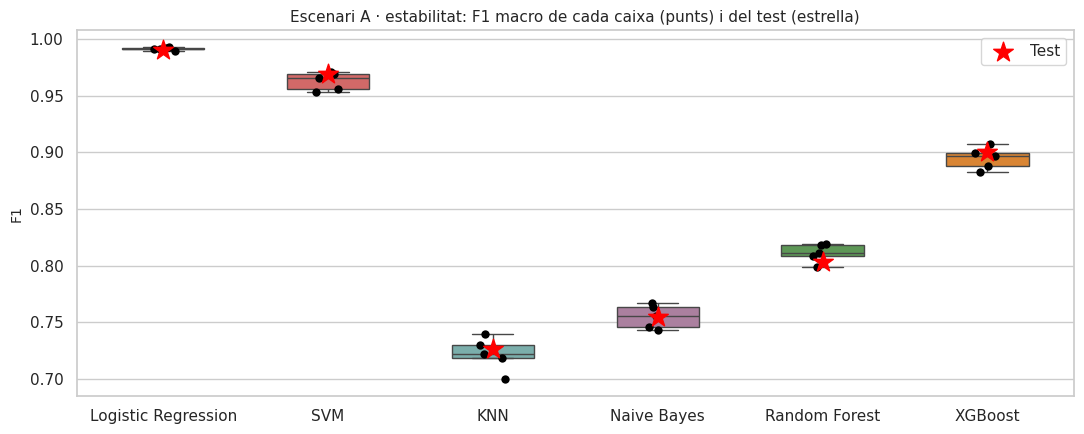

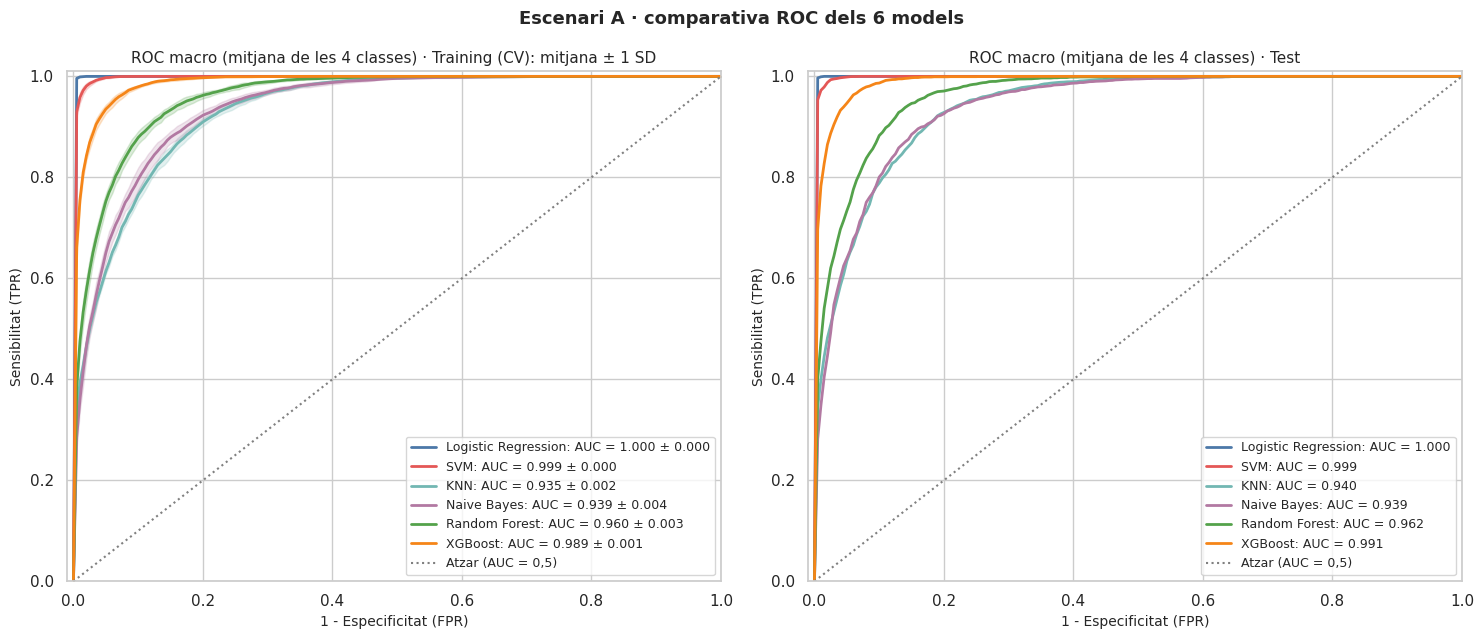

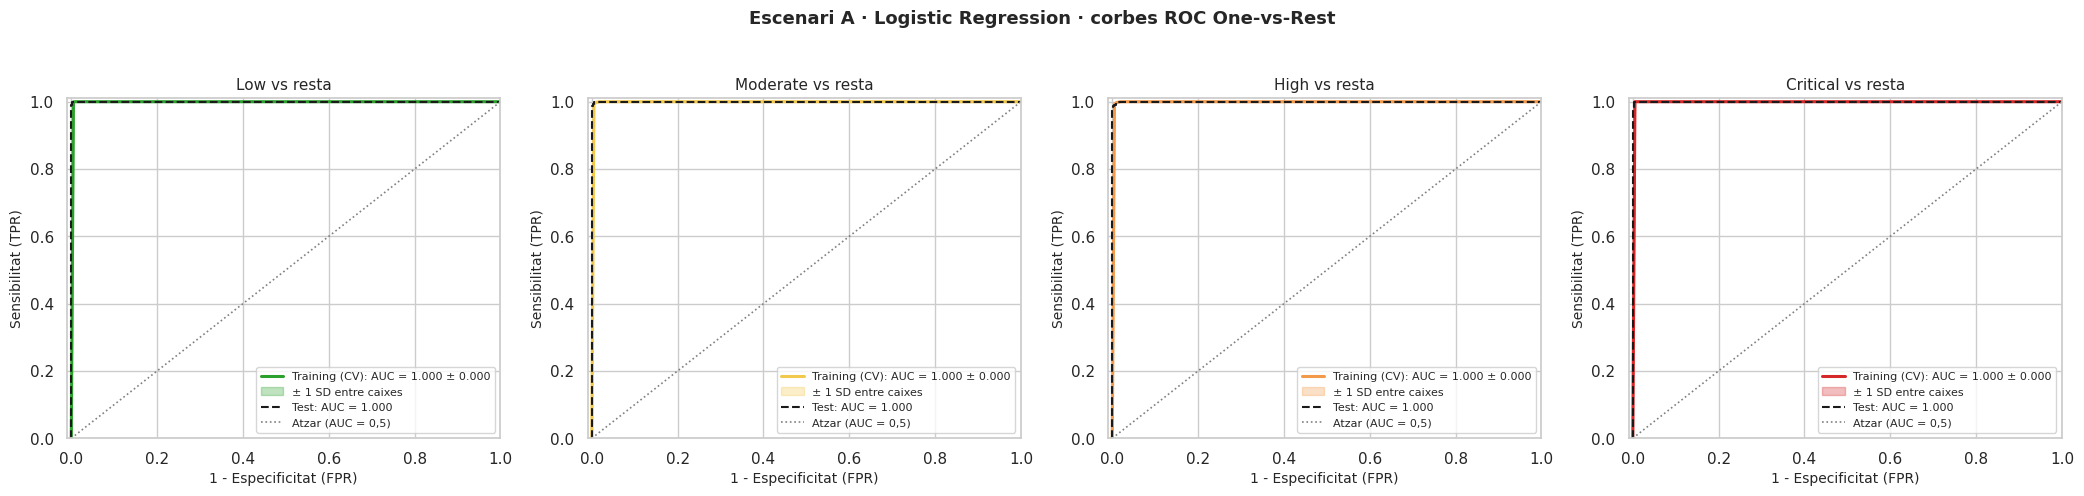

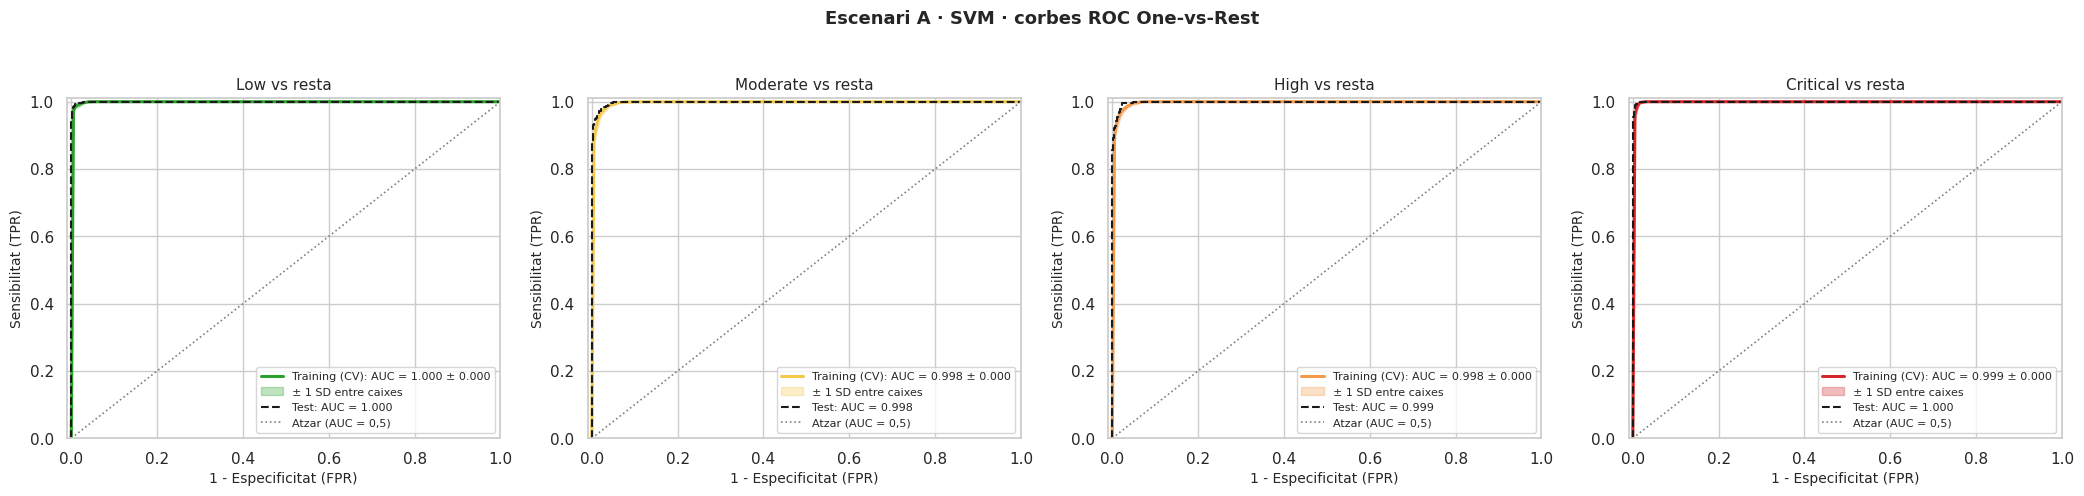

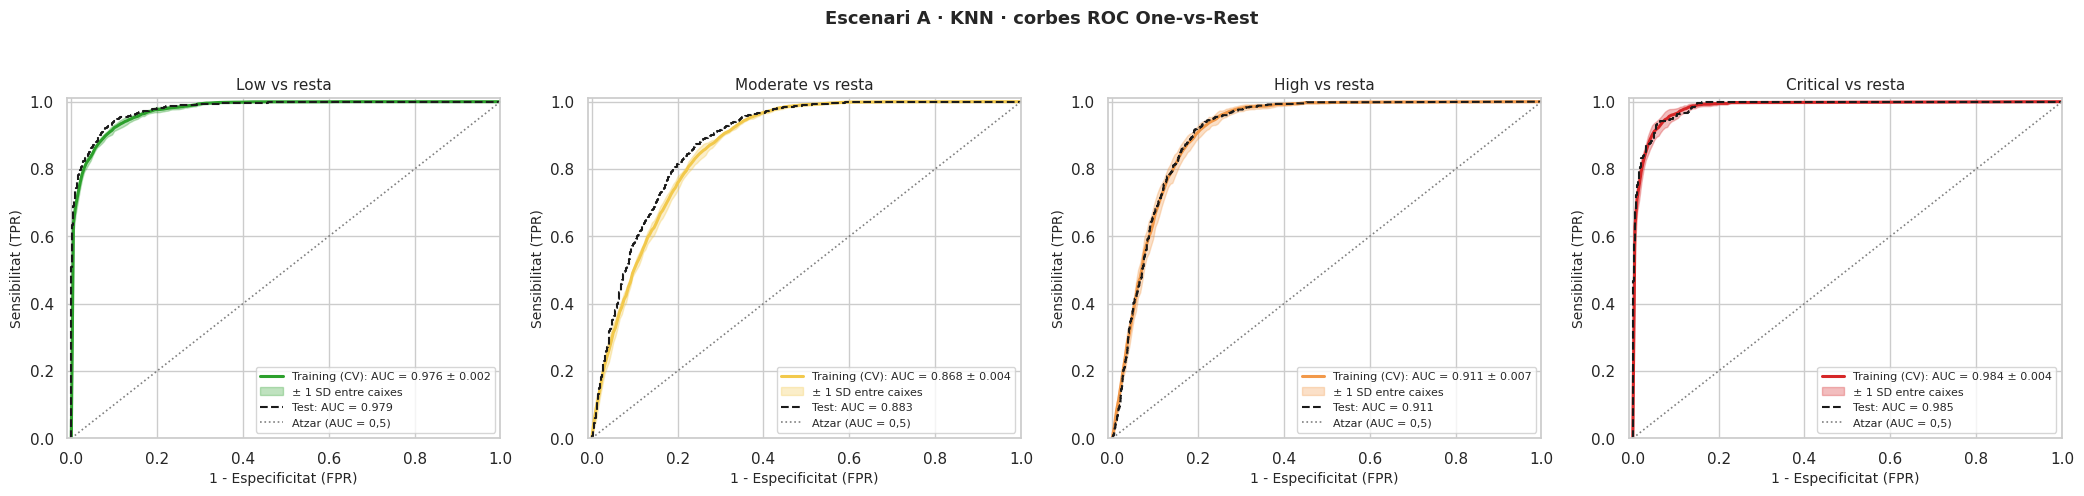

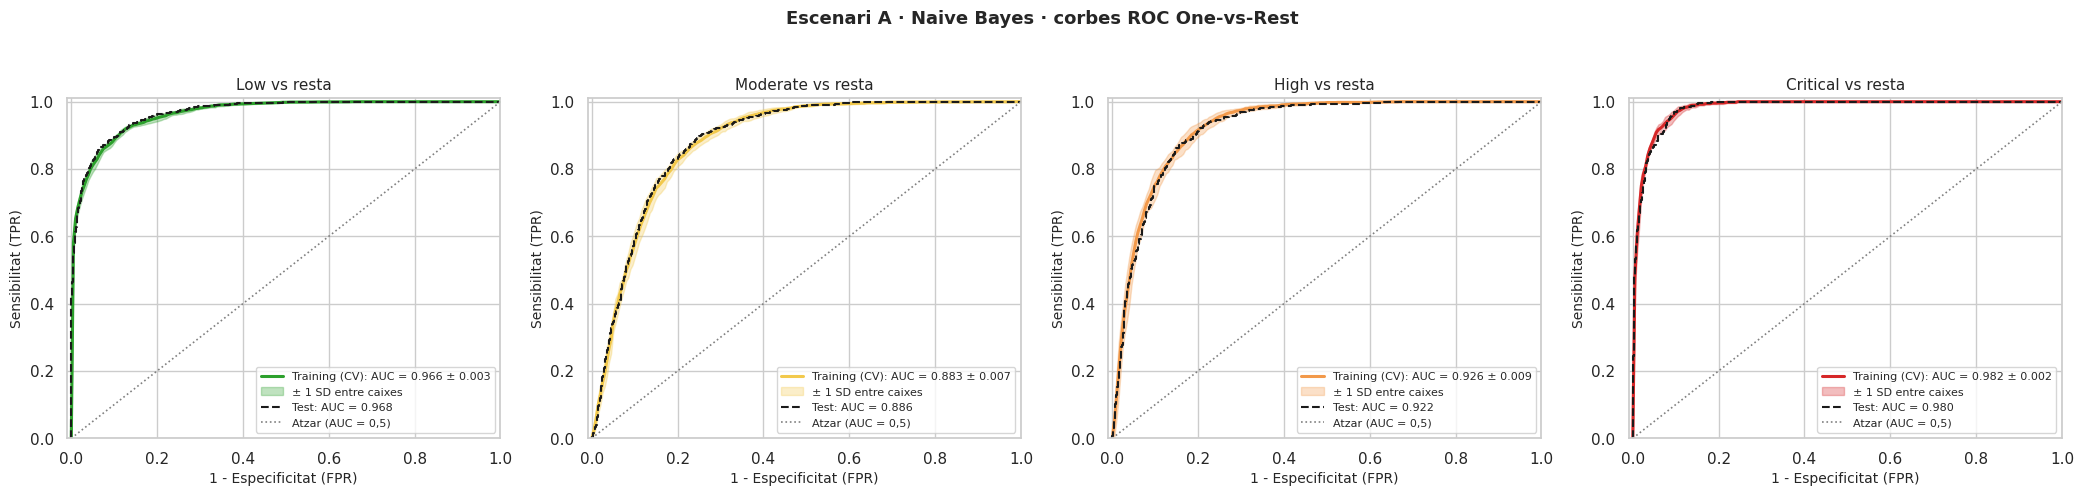

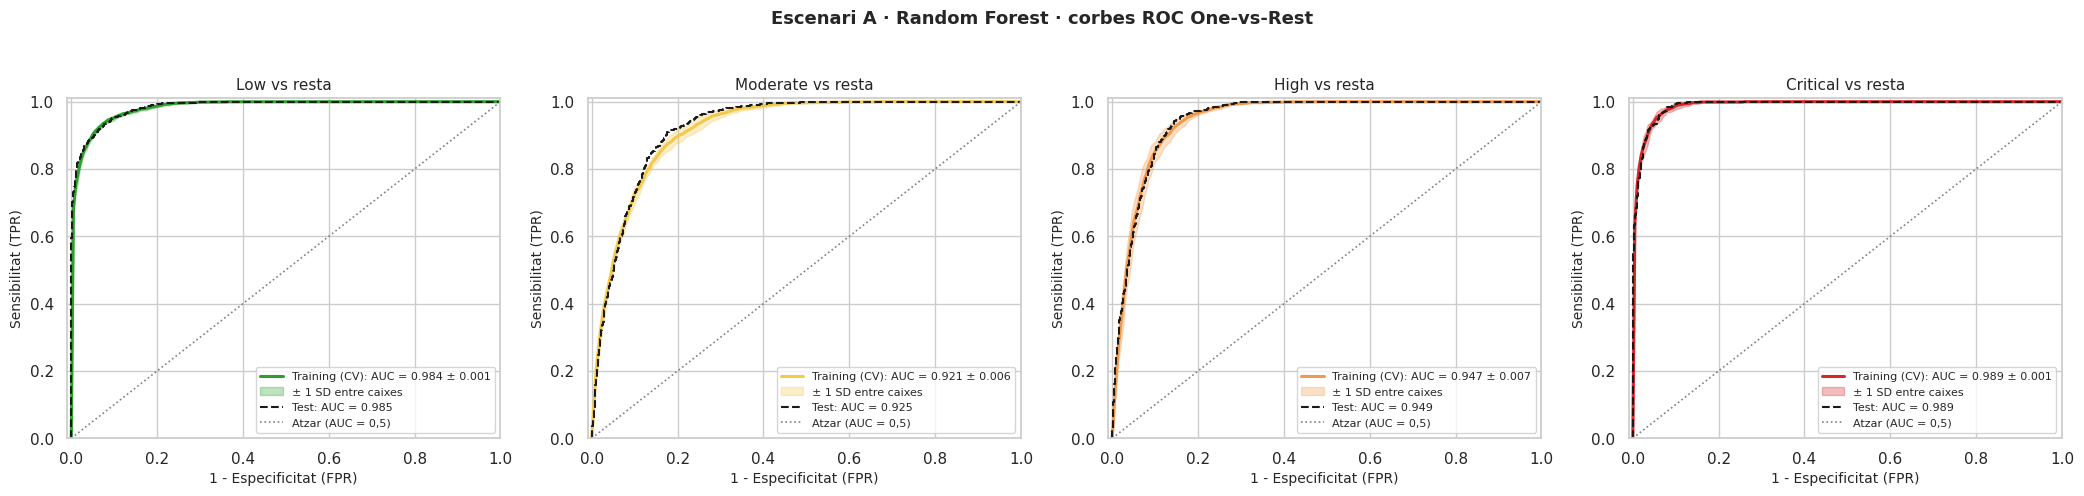

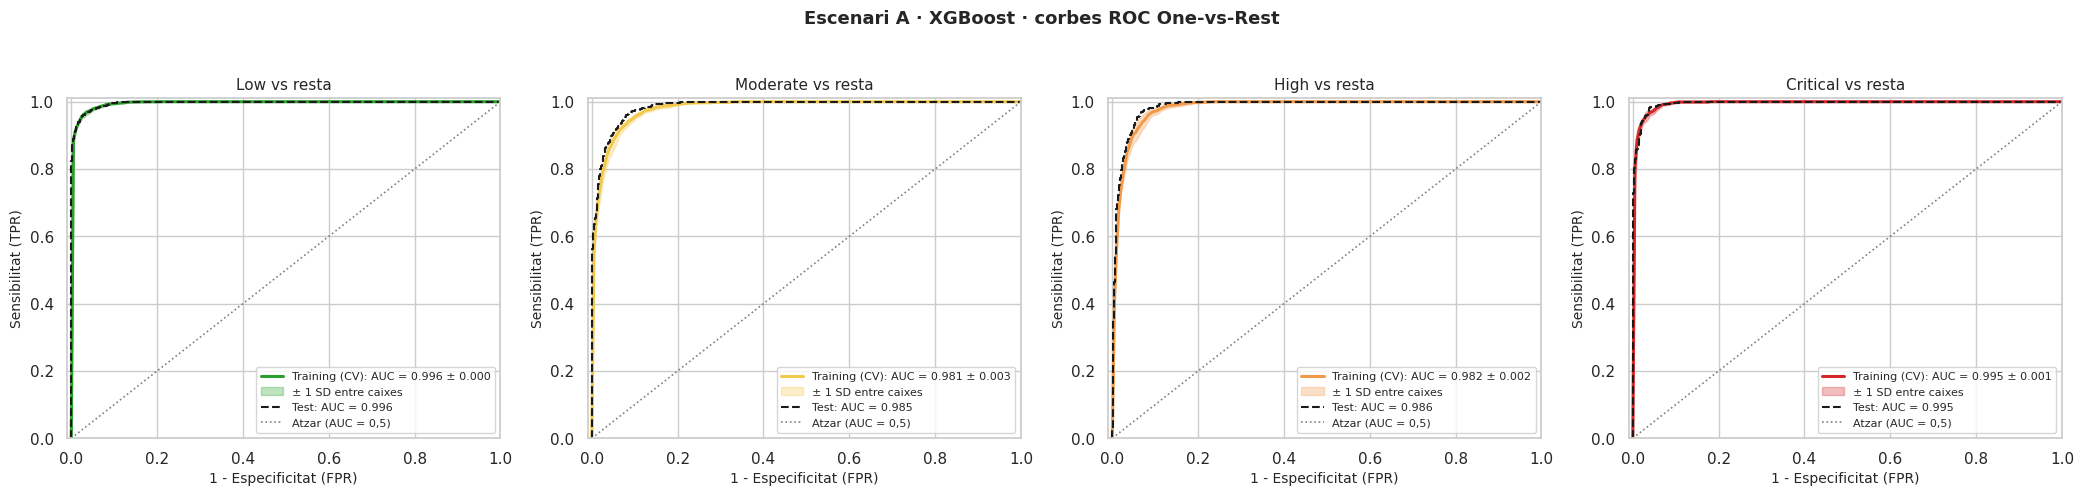

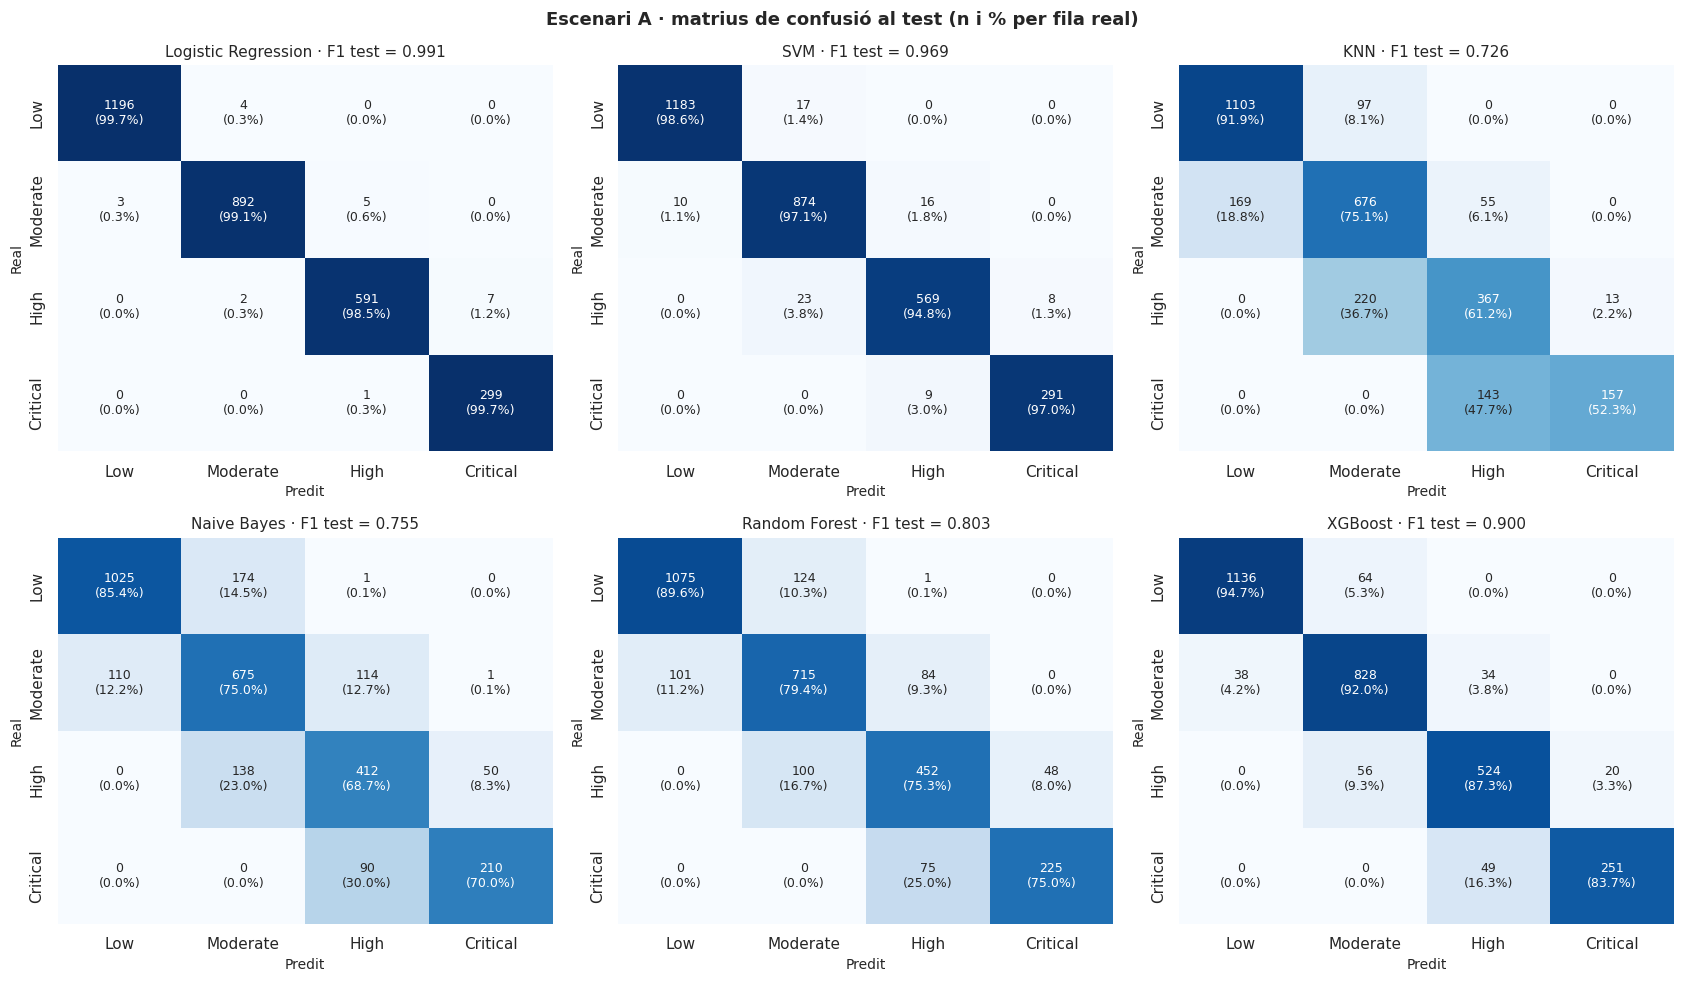

In [ ]:
mostrar_grafics(res_A, "A")

### Cel·la 15 · ESCENARI B: entrenament (variables filtrades)

In [ ]:
t0 = time.time()
res_B = executar_escenari("B", VARS_B)
print(f"\nTemps total de l'Escenari B: {(time.time() - t0) / 60:.1f} min")

ESCENARI B · 22 variables

▶ Logistic Regression · millors hiperparàmetres: {'C': 100, 'class_weight': 'balanced'}
   Caixa 1/5 · F1 = 0.9137 · Accuracy = 0.9200 · AUC = 0.9924   (F1 a les caixes d'entrenament = 0.9106)
   Caixa 2/5 · F1 = 0.8989 · Accuracy = 0.9067 · AUC = 0.9900   (F1 a les caixes d'entrenament = 0.9139)
   Caixa 3/5 · F1 = 0.8955 · Accuracy = 0.9038 · AUC = 0.9888   (F1 a les caixes d'entrenament = 0.9169)
   Caixa 4/5 · F1 = 0.9109 · Accuracy = 0.9208 · AUC = 0.9915   (F1 a les caixes d'entrenament = 0.9127)
   Caixa 5/5 · F1 = 0.9213 · Accuracy = 0.9258 · AUC = 0.9926   (F1 a les caixes d'entrenament = 0.9087)
   ➜ F1 CV = 0.9081 ± 0.0107 (rang 0.8955–0.9213) · ESTABLE ✔ · F1 Test = 0.9052 · 10 s

▶ SVM · millors hiperparàmetres: {'C': 1, 'class_weight': 'balanced', 'gamma': 0.01}
   Caixa 1/5 · F1 = 0.9097 · Accuracy = 0.9158 · AUC = 0.9917   (F1 a les caixes d'entrenament = 0.9138)
   Caixa 2/5 · F1 = 0.8977 · Accuracy = 0.9025 · AUC = 0.9902   (F1 a les caixes 

### Cel·la 16 · ESCENARI B: taules

In [ ]:
mostrar_taules(res_B, "B")

ESCENARI B · TAULA DE MÈTRIQUES (Training = mitjana ± SD de 5 caixes · Test = valor únic)


Accuracy                          Precision               Recall (Sensitivity)                           F1-score                                AUC                        Specificity          \
                    Training (CV) mitjana ± SD    Test Training (CV) mitjana ± SD    Test Training (CV) mitjana ± SD    Test Training (CV) mitjana ± SD    Test Training (CV) mitjana ± SD    Test Training (CV) mitjana ± SD    Test   
Logistic Regression            0.9154 ± 0.0096  0.9110            0.9030 ± 0.0117  0.8990            0.9141 ± 0.0105  0.9121            0.9081 ± 0.0107  0.9052            0.9911 ± 0.0016  0.9912            0.9711 ± 0.0032  0.9697   
SVM                            0.9099 ± 0.0090  0.9057            0.8972 ± 0.0097  0.8917            0.9102 ± 0.0088  0.9068            0.9032 ± 0.0089  0.8988            0.9909 ± 0.0014  0.9911            0.9695 ± 0.0030  0.9682   
KNN                            0.7705 ± 0.0089  0.7753            0.7872 ± 0.0075  0.7827            0.7102 ± 0.0136  0.7124            0.7350 ± 0.0131  0.7356            0.9408 ± 0.0041  0.9428            0.9180 ± 0.0031  0.9200   
Naive Bayes                    0.7662 ± 0.0073  0.7663            0.7664 ± 0.0072  0.7586            0.7429 ± 0.0120  0.7390            0.7516 ± 0.0091  0.7463            0.9391 ± 0.0038  0.9375            0.9186 ± 0.0023  0.9192   
Random Forest                  0.8181 ± 0.0098  0.8220            0.8220 ± 0.0080  0.8163            0.7824 ± 0.0124  0.7826            0.7985 ± 0.0108  0.7966            0.9595 ± 0.0037  0.9617            0.9355 ± 0.0034  0.9374   
XGBoost                        0.8798 ± 0.0071  0.8747            0.8771 ± 0.0089  0.8644            0.8573 ± 0.0077  0.8515            0.8659 ± 0.0083  0.8571            0.9813 ± 0.0011  0.9823            0.9580 ± 0.0024  0.9567   

                                Kappa ponderat          
                    Training (CV) mitjana ± SD    Test  
Logistic Regression            0.9582 ± 0.0047  0.9559  
SVM                            0.9553 ± 0.0045  0.9532  
KNN                            0.8727 ± 0.0074  0.8765  
Naive Bayes                    0.8758 ± 0.0057  0.8769  
Random Forest                  0.9042 ± 0.0067  0.9072  
XGBoost                        0.9381 ± 0.0037  0.9359


CONTROL D'ESTABILITAT · F1 macro de cada caixa de validació


,Caixa 1,Caixa 2,Caixa 3,Caixa 4,Caixa 5,mitjana,SD,rang (màx-mín),estable
Logistic Regression,0.9137,0.8989,0.8955,0.9109,0.9213,0.9081,0.0107,0.0258,✔
SVM,0.9097,0.8977,0.8925,0.9014,0.9145,0.9032,0.0089,0.0220,✔
KNN,0.7457,0.7204,0.7211,0.7425,0.7453,0.7350,0.0131,0.0253,✔
Naive Bayes,0.7565,0.7518,0.7375,0.7499,0.7620,0.7515,0.0091,0.0245,✔
Random Forest,0.8054,0.8022,0.7800,0.8063,0.7983,0.7984,0.0108,0.0263,✔
XGBoost,0.8801,0.8657,0.8597,0.8638,0.8603,0.8659,0.0083,0.0204,✔



AUC PER CLASSE (One-vs-Rest)


Low                 Moderate                     High                 Critical        
                            Training    Test         Training    Test         Training    Test         Training    Test
Logistic Regression  0.9961 ± 0.0005  0.9961  0.9833 ± 0.0026  0.9828  0.9875 ± 0.0026  0.9882  0.9973 ± 0.0010  0.9976
SVM                  0.9960 ± 0.0005  0.9959  0.9832 ± 0.0023  0.9827  0.9875 ± 0.0023  0.9881  0.9970 ± 0.0008  0.9976
KNN                  0.9775 ± 0.0011  0.9814  0.8829 ± 0.0068  0.8921  0.9180 ± 0.0087  0.9158  0.9849 ± 0.0035  0.9817
Naive Bayes          0.9680 ± 0.0024  0.9690  0.8832 ± 0.0067  0.8844  0.9239 ± 0.0093  0.9183  0.9814 ± 0.0016  0.9784
Random Forest        0.9832 ± 0.0010  0.9848  0.9218 ± 0.0075  0.9307  0.9431 ± 0.0071  0.9426  0.9898 ± 0.0012  0.9886
XGBoost              0.9928 ± 0.0004  0.9931  0.9663 ± 0.0028  0.9704  0.9727 ± 0.0021  0.9733  0.9935 ± 0.0011  0.9925


COMPROVACIÓ DE SOBREAJUST (F1 macro)


,F1 caixes d'entrenament,F1 caixes de validació,F1 test,diferència entrenament - test
Logistic Regression,0.9126,0.9081,0.9052,0.0073
SVM,0.9147,0.9032,0.8988,0.0159
KNN,1.0000,0.7350,0.7356,0.2644
Naive Bayes,0.7549,0.7516,0.7463,0.0086
Random Forest,1.0000,0.7985,0.7966,0.2034
XGBoost,0.9800,0.8659,0.8571,0.1229



MILLORS HIPERPARÀMETRES (Grid Search)


,C,class_weight,gamma,metric,n_neighbors,weights,var_smoothing,max_depth,min_samples_leaf,n_estimators,learning_rate,subsample
Logistic Regression,100,balanced,—,—,—,—,—,—,—,—,—,—
SVM,1,balanced,0.01,—,—,—,—,—,—,—,—,—
KNN,—,—,—,manhattan,21,distance,—,—,—,—,—,—
Naive Bayes,—,—,—,—,—,—,1e-09,—,—,—,—,—
Random Forest,—,None,—,—,—,—,—,None,1,400,—,—
XGBoost,—,—,—,—,—,—,—,3,—,400,0.1,0.8


### Cel·la 17 · ESCENARI B: gràfics (estabilitat, ROC i matrius de confusió)

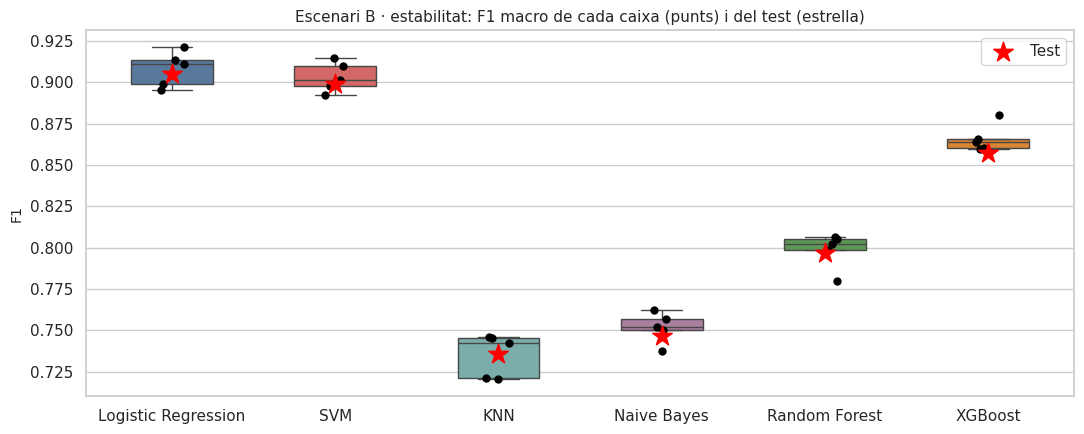

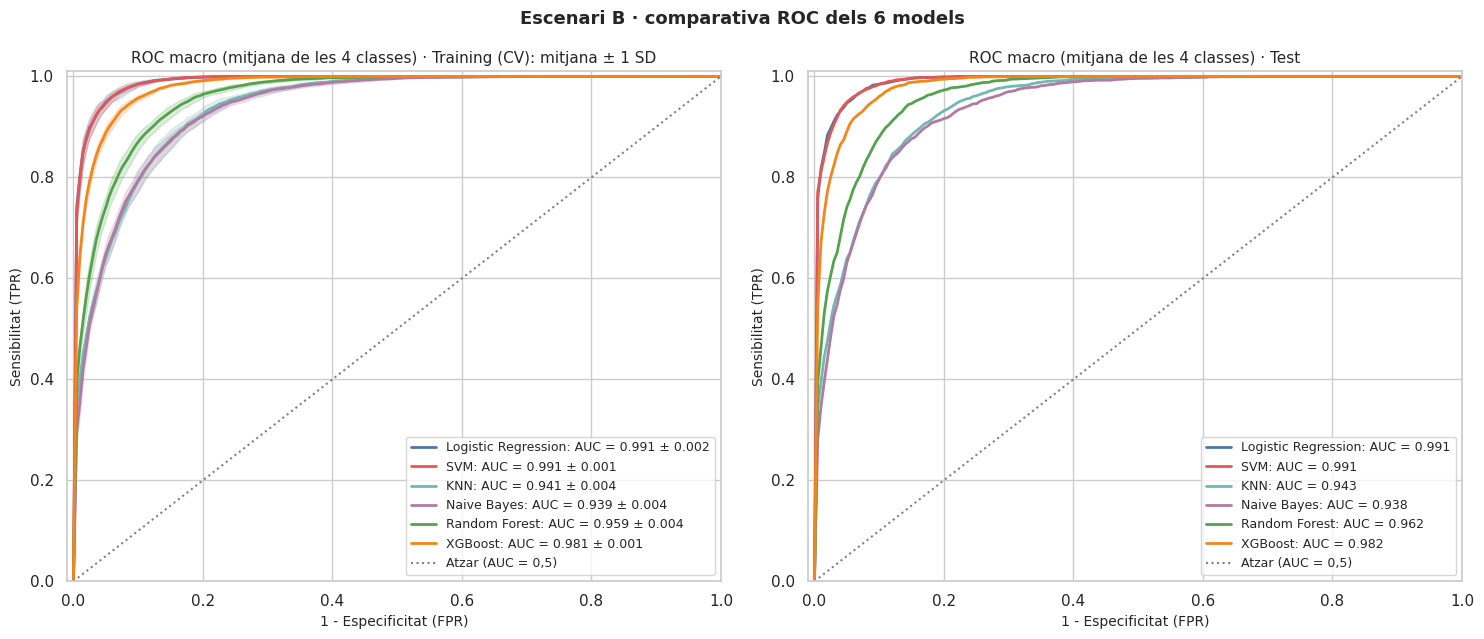

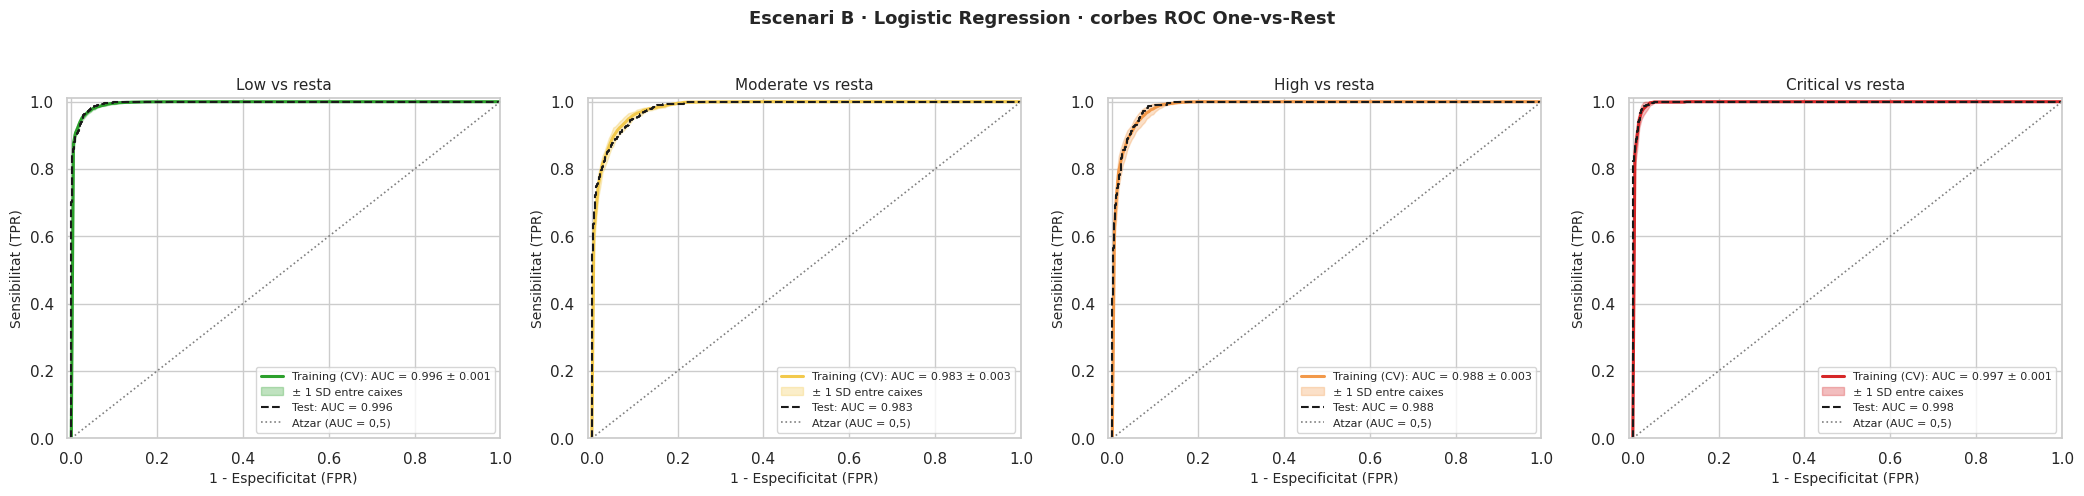

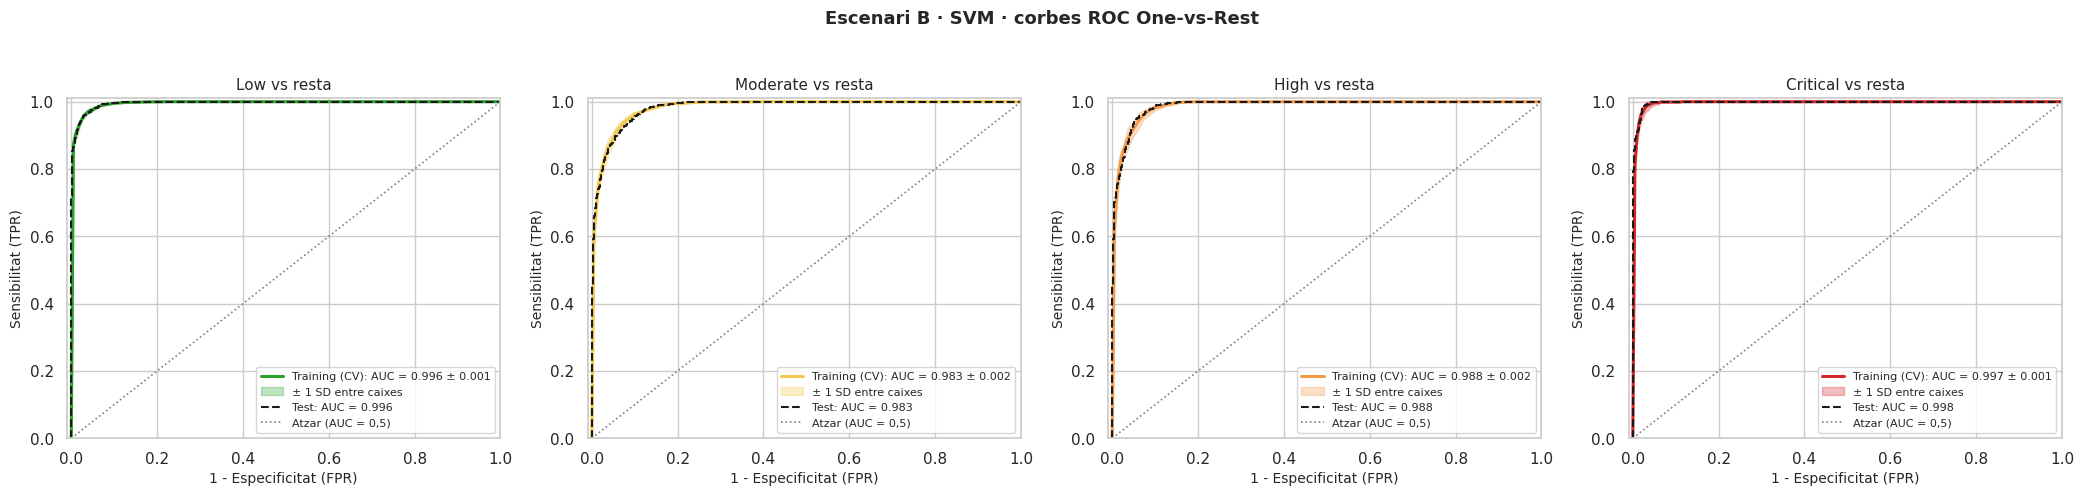

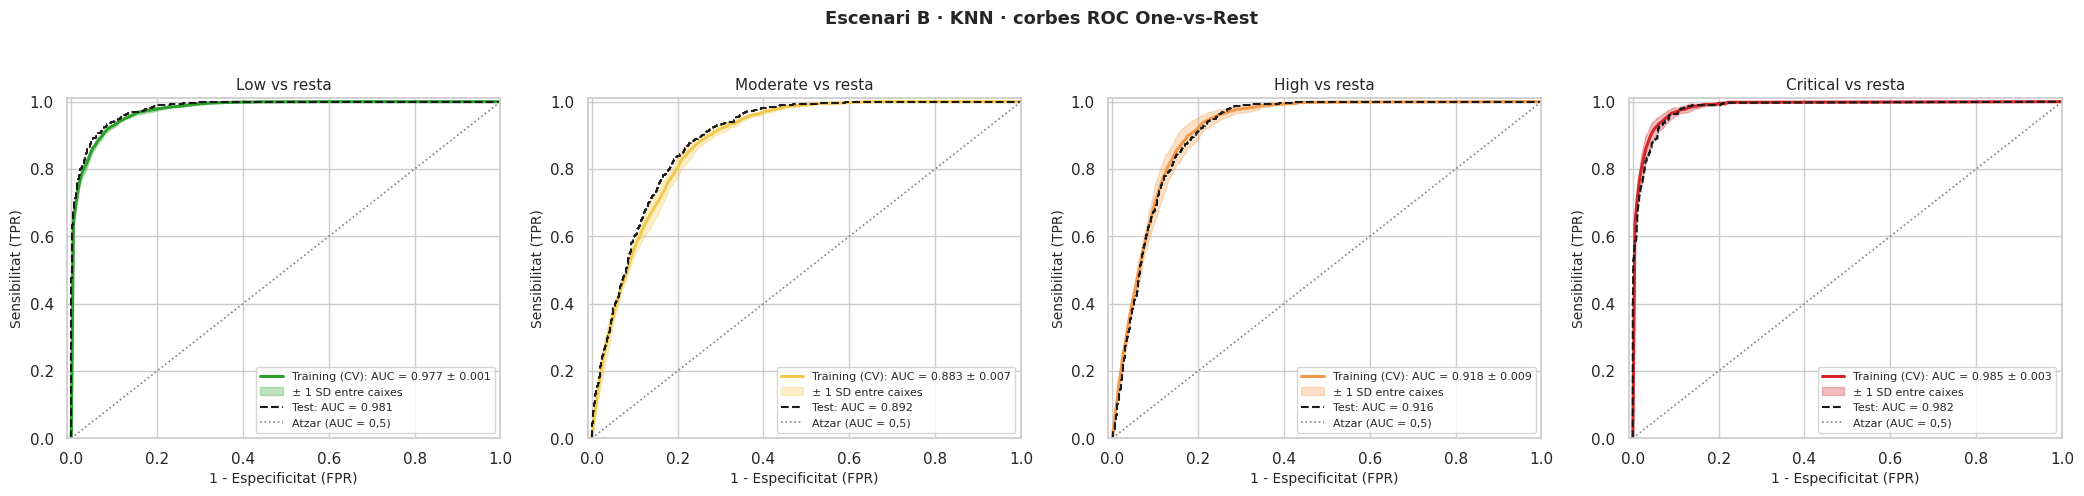

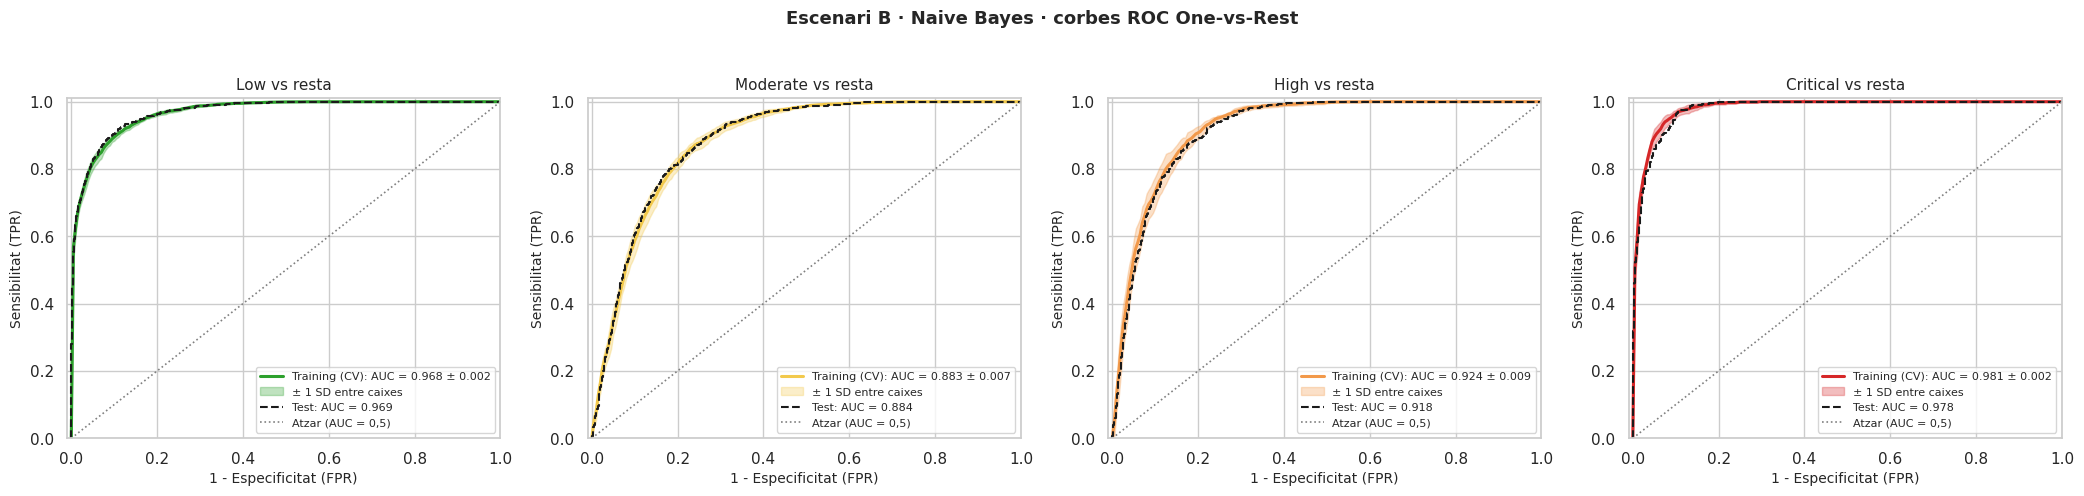

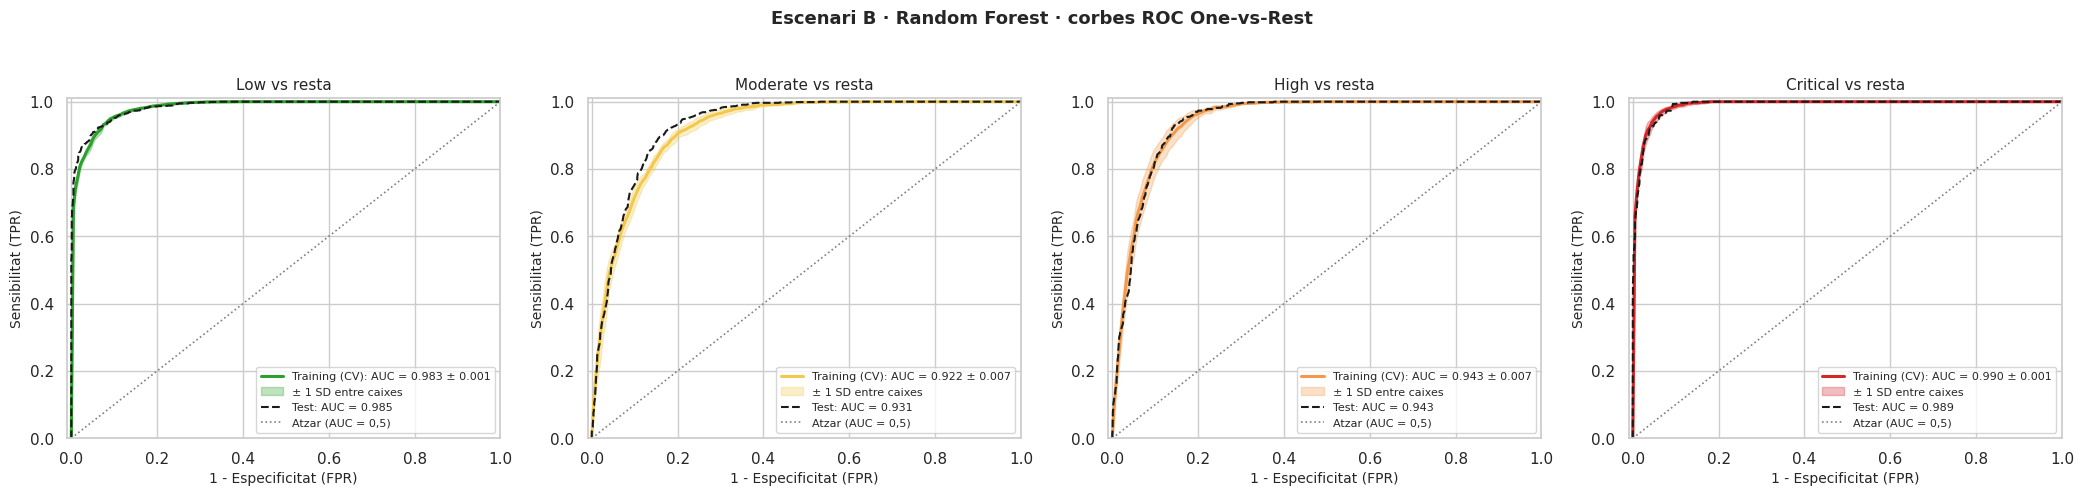

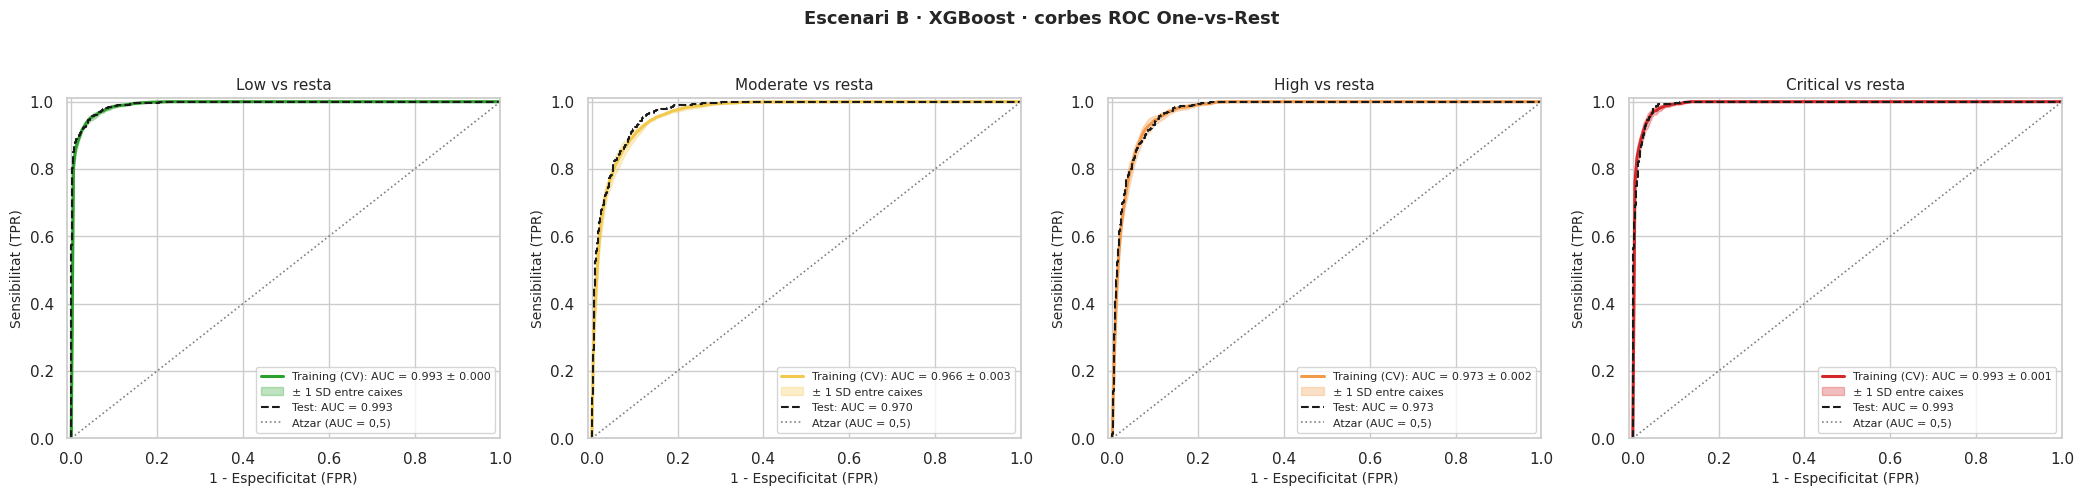

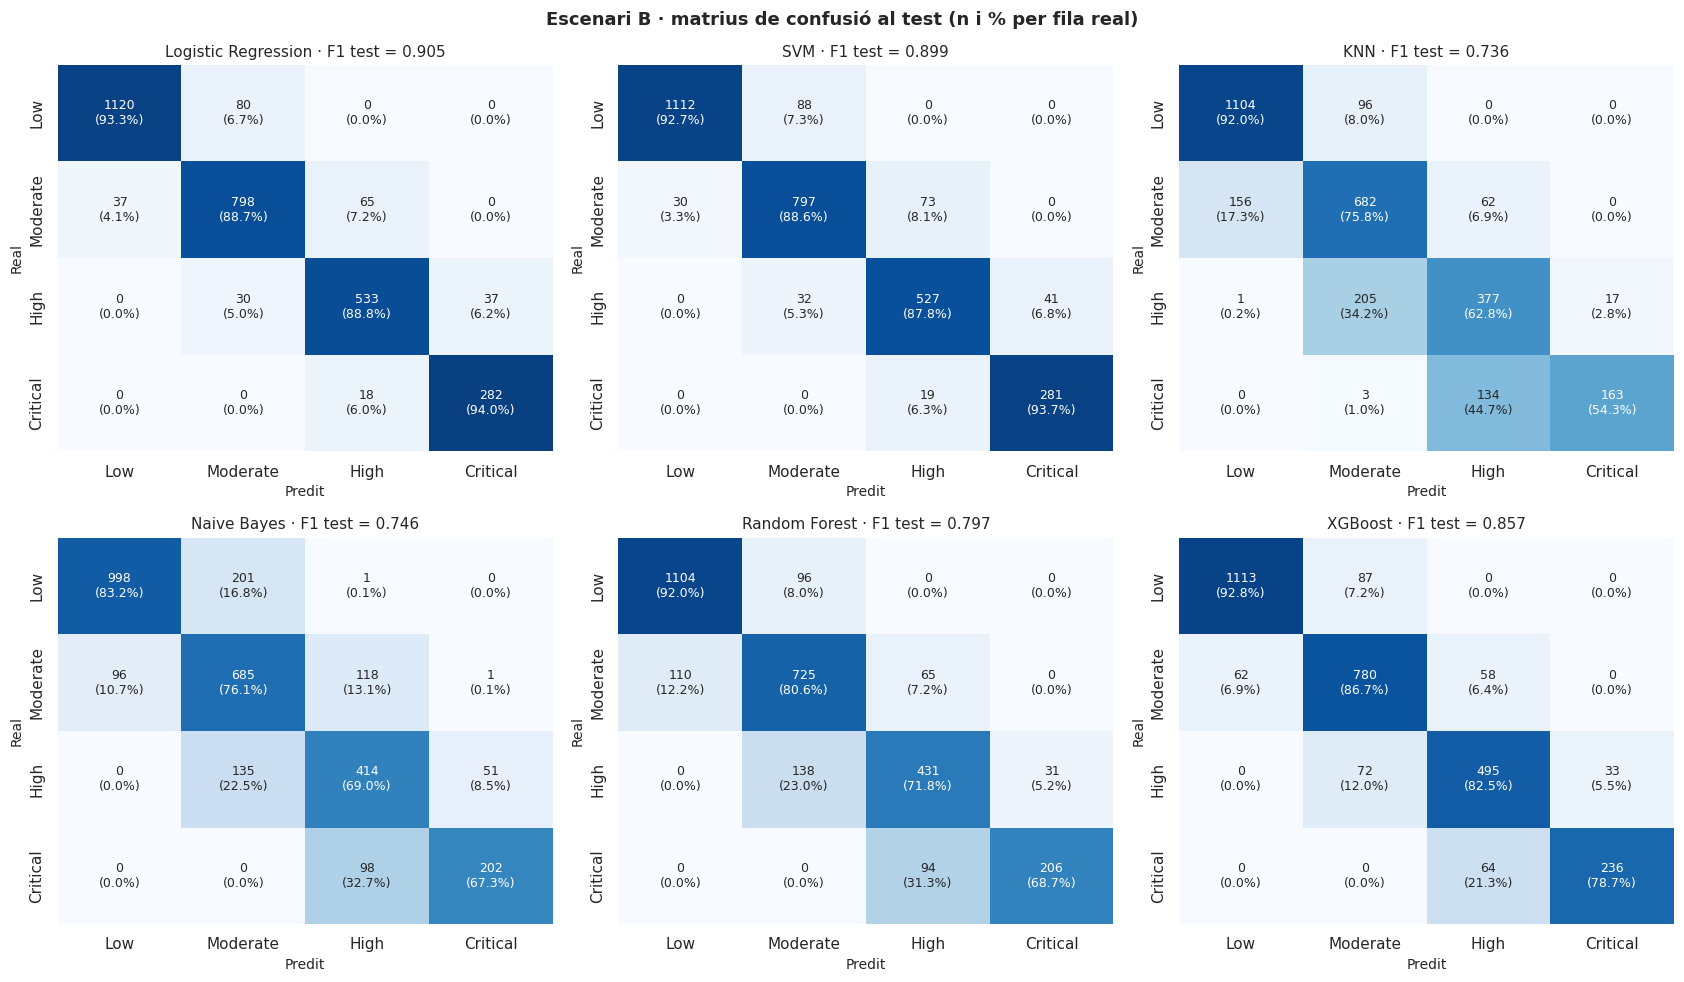

In [ ]:
mostrar_grafics(res_B, "B")

### Cel·la 18 · Comparativa final: Escenari A vs Escenari B
La taula posa costat per costat els 6 models en tots dos escenaris. El **millor model** de cada escenari es tria per l'**F1 de la validació creuada**, i no pel test, perquè el test ha de quedar com una avaluació independent.

COMPARATIVA FINAL · Escenari A (32 variables) vs Escenari B (22 variables)


F1-score                                            Accuracy                                           Precision                                    Recall (Sensitivity)                                     \
                        A · Training A · Test     B · Training B · Test     A · Training A · Test     B · Training B · Test     A · Training A · Test     B · Training B · Test         A · Training A · Test     B · Training B · Test   
Logistic Regression  0.9916 ± 0.0013   0.9909  0.9081 ± 0.0107   0.9052  0.9923 ± 0.0011   0.9927  0.9154 ± 0.0096   0.9110  0.9905 ± 0.0018   0.9895  0.9030 ± 0.0117   0.8990      0.9927 ± 0.0009   0.9924  0.9141 ± 0.0105   0.9121   
SVM                  0.9633 ± 0.0082   0.9693  0.9032 ± 0.0089   0.8988  0.9675 ± 0.0073   0.9723  0.9099 ± 0.0090   0.9057  0.9651 ± 0.0077   0.9698  0.8972 ± 0.0097   0.8917      0.9616 ± 0.0087   0.9688  0.9102 ± 0.0088   0.9068   
KNN                  0.7217 ± 0.0148   0.7262  0.7350 ± 0.0131   0.7356  0.7566 ± 0.0078   0.7677  0.7705 ± 0.0089   0.7753  0.7776 ± 0.0111   0.7802  0.7872 ± 0.0075   0.7827      0.6956 ± 0.0142   0.7013  0.7102 ± 0.0136   0.7124   
Naive Bayes          0.7550 ± 0.0103   0.7548  0.7516 ± 0.0091   0.7463  0.7706 ± 0.0097   0.7740  0.7662 ± 0.0073   0.7663  0.7687 ± 0.0072   0.7648  0.7664 ± 0.0072   0.7586      0.7462 ± 0.0123   0.7477  0.7429 ± 0.0120   0.7390   
Random Forest        0.8112 ± 0.0082   0.8034  0.7985 ± 0.0108   0.7966  0.8250 ± 0.0069   0.8223  0.8181 ± 0.0098   0.8220  0.8186 ± 0.0085   0.8096  0.8220 ± 0.0080   0.8163      0.8053 ± 0.0085   0.7984  0.7824 ± 0.0124   0.7826   
XGBoost              0.8950 ± 0.0096   0.9001  0.8659 ± 0.0083   0.8571  0.9078 ± 0.0081   0.9130  0.8798 ± 0.0071   0.8747  0.9063 ± 0.0096   0.9076  0.8771 ± 0.0089   0.8644      0.8862 ± 0.0095   0.8942  0.8573 ± 0.0077   0.8515   

                                 AUC                                          F1-score  
                        A · Training A · Test     B · Training B · Test Δ Test (B − A)  
Logistic Regression  0.9999 ± 0.0000   0.9999  0.9911 ± 0.0016   0.9912        -0.0857  
SVM                  0.9987 ± 0.0003   0.9991  0.9909 ± 0.0014   0.9911        -0.0705  
KNN                  0.9347 ± 0.0021   0.9397  0.9408 ± 0.0041   0.9428        +0.0094  
Naive Bayes          0.9393 ± 0.0041   0.9389  0.9391 ± 0.0038   0.9375        -0.0085  
Random Forest        0.9604 ± 0.0030   0.9619  0.9595 ± 0.0037   0.9617        -0.0069  
XGBoost              0.9885 ± 0.0008   0.9906  0.9813 ± 0.0011   0.9823        -0.0430

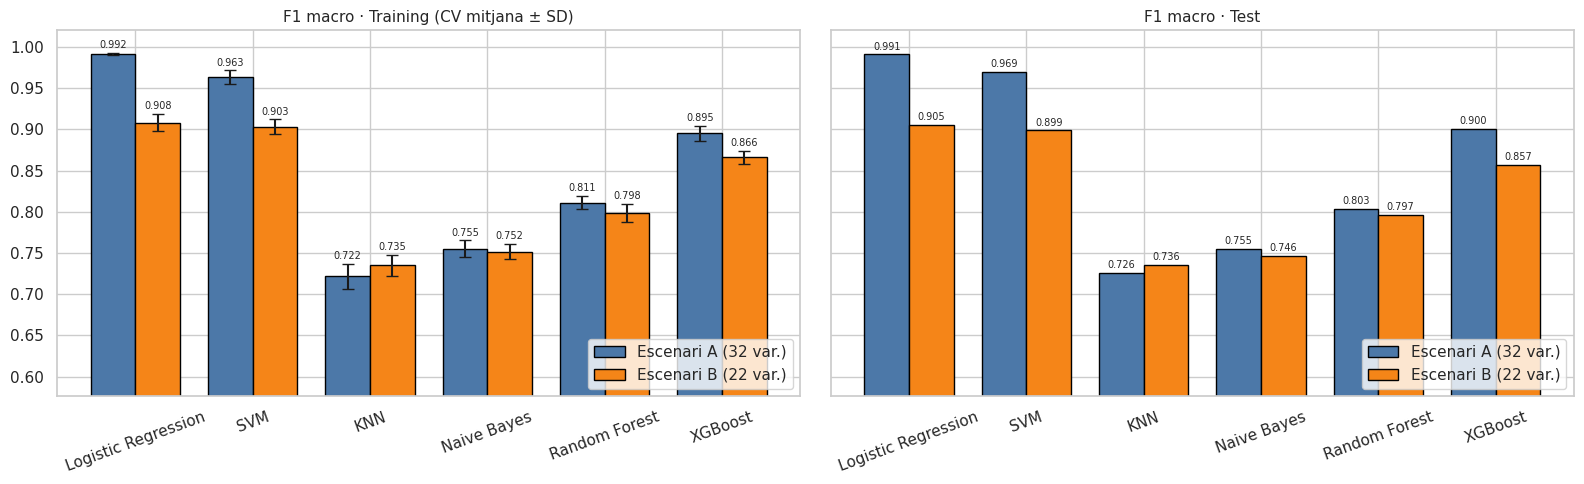

Millor model Escenari A: Logistic Regression · F1 CV = 0.9916 ± 0.0013 · F1 test = 0.9909 · AUC test = 0.9999
Millor model Escenari B: Logistic Regression · F1 CV = 0.9081 ± 0.0107 · F1 test = 0.9052 · AUC test = 0.9912


In [ ]:
def resum_numeric(res, esc):
    files = []
    for m, r in res.items():
        f = {"Escenari": esc, "Model": m, "Nº variables": len(VARS_A if esc == "A" else VARS_B)}
        for met in METRIQUES:
            f[f"{met} CV mitjana"] = r["cv_val"][met].mean(); f[f"{met} CV SD"] = r["cv_val"][met].std(ddof=1)
            f[f"{met} Test"] = r["test"][met]
        f["Temps (s)"] = r["temps_s"]; files.append(f)
    return pd.DataFrame(files)

comp = pd.concat([resum_numeric(res_A, "A"), resum_numeric(res_B, "B")], ignore_index=True)

# Taula costat a costat
cara = {}
for m in MODELS:
    a, b = res_A[m], res_B[m]; fila = {}
    for met in ["F1-score", "Accuracy", "Precision", "Recall (Sensitivity)", "AUC"]:
        for esc, r in (("A", a), ("B", b)):
            fila[(met, f"{esc} · Training")] = f"{r['cv_val'][met].mean():.4f} ± {r['cv_val'][met].std(ddof=1):.4f}"
            fila[(met, f"{esc} · Test")] = f"{r['test'][met]:.4f}"
    fila[("F1-score", "Δ Test (B − A)")] = f"{b['test']['F1-score'] - a['test']['F1-score']:+.4f}"
    cara[m] = fila
cara = pd.DataFrame.from_dict(cara, orient="index"); cara.columns = pd.MultiIndex.from_tuples(cara.columns)
print(f"COMPARATIVA FINAL · Escenari A ({len(VARS_A)} variables) vs Escenari B ({len(VARS_B)} variables)")
display(cara)

# Gràfic: F1 (CV mitjana ± SD i test) per model i escenari
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
x = np.arange(len(MODELS)); w = 0.38
for ax, tipus in zip(axes, ["CV", "Test"]):
    for i, (esc, col) in enumerate((("A", "#4C78A8"), ("B", "#F58518"))):
        s = comp[comp["Escenari"] == esc].set_index("Model").reindex(list(MODELS))
        alt = s["F1-score CV mitjana"] if tipus == "CV" else s["F1-score Test"]
        err = s["F1-score CV SD"] if tipus == "CV" else None
        bars = ax.bar(x + (i - 0.5) * w, alt, w, yerr=err, capsize=4, color=col, edgecolor="black",
                      label=f"Escenari {esc} ({len(VARS_A if esc == 'A' else VARS_B)} var.)")
        ax.bar_label(bars, labels=[f"{v:.3f}" for v in alt], fontsize=7, padding=2)
    ax.set_xticks(x); ax.set_xticklabels(list(MODELS), rotation=20)
    ax.set_title("F1 macro · Training (CV mitjana ± SD)" if tipus == "CV" else "F1 macro · Test")
    ax.set_ylim(max(0, comp["F1-score Test"].min() - 0.15), 1.02); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

# Millor model de cada escenari (triat per la CV)
for esc in ("A", "B"):
    s = comp[comp["Escenari"] == esc].sort_values("F1-score CV mitjana", ascending=False).iloc[0]
    print(f"Millor model Escenari {esc}: {s['Model']} · F1 CV = {s['F1-score CV mitjana']:.4f} ± {s['F1-score CV SD']:.4f} · "
          f"F1 test = {s['F1-score Test']:.4f} · AUC test = {s['AUC Test']:.4f}")

### Cel·la 19 · Informe per classe del millor model i exportació dels resultats

In [ ]:
for esc, res in (("A", res_A), ("B", res_B)):
    millor = max(res, key=lambda m: res[m]["cv_val"]["F1-score"].mean())
    print(f"\nESCENARI {esc} · {millor} · informe per classe al TEST")
    print(classification_report(y_test, res[millor]["pred_test"], target_names=ETIQ, digits=4))

comp.round(5).to_csv("llibreta3_comparativa.csv", index=False)
pd.concat([r["cv_val"].assign(Escenari=e, Model=m) for e, res in (("A", res_A), ("B", res_B)) for m, r in res.items()]
          ).to_csv("llibreta3_resultats_per_caixa.csv")
pd.concat([taula_params(res_A).assign(Escenari="A"), taula_params(res_B).assign(Escenari="B")]).to_csv("llibreta3_hiperparametres.csv")
pd.Series(VARS_B, name="variables_escenari_B").to_csv("llibreta3_variables_B.csv", index=False)
print("Desats: llibreta3_comparativa.csv · llibreta3_resultats_per_caixa.csv · llibreta3_hiperparametres.csv · llibreta3_variables_B.csv")


ESCENARI A · Logistic Regression · informe per classe al TEST
              precision    recall  f1-score   support

         Low     0.9975    0.9967    0.9971      1200
    Moderate     0.9933    0.9911    0.9922       900
        High     0.9899    0.9850    0.9875       600
    Critical     0.9771    0.9967    0.9868       300

    accuracy                         0.9927      3000
   macro avg     0.9895    0.9924    0.9909      3000
weighted avg     0.9927    0.9927    0.9927      3000


ESCENARI B · Logistic Regression · informe per classe al TEST
              precision    recall  f1-score   support

         Low     0.9680    0.9333    0.9504      1200
    Moderate     0.8789    0.8867    0.8827       900
        High     0.8653    0.8883    0.8766       600
    Critical     0.8840    0.9400    0.9111       300

    accuracy                         0.9110      3000
   macro avg     0.8990    0.9121    0.9052      3000
weighted avg     0.9123    0.9110    0.9114      3000

Desa

### Guia per interpretar els resultats (per a la memòria)
1. **Estabilitat:** si la SD de l'F1 entre caixes és petita (< 0,02) i el rang és estret, el model no depèn de quines dades li toquen.
2. **Sobreajust:** compara l'F1 de les caixes d'entrenament amb el de validació i el de test. Una diferència gran (> 0,05) indica que el model memoritza. És habitual en KNN amb `weights="distance"` i en Random Forest sense límit de profunditat, i en aquests casos cal comentar-ho.
3. **Training vs Test:** si l'F1 del test cau dins de mitjana ± SD de la CV, el model generalitza bé.
4. **A vs B:** si l'Escenari B dona un F1 igual o molt semblant amb menys variables, el filtratge de la Llibreta 2 queda justificat: el model és més simple, igual de bo i més interpretable.
5. **Rendiment molt alt:** si diversos models superen el 95 %, és coherent amb la Llibreta 1 (la glucosa en dejú i l'HbA1c tenen ε² ≈ 0,5). Probablement el dataset és sintètic i generat per regles, i cal dir-ho a la discussió.